# Cluster E – N-Body simulation: Teams 17, 18, 19 (+ Team 20 precision study)
**Everything in one Colab notebook.** Run the cells top to bottom.

| Part | Team / Problem | Platform | Programs |
|---|---|---|---|
| A | – | setup + shared header | `nbody_common.hpp` |
| B | Team 17 / P17 | shared-memory CPU (sequential, OpenMP, Pthreads) | `nbody_smp.cpp` |
| C | Team 18 / P18 | distributed CPU (MPI) | `nbody_mpi.cpp` |
| D | Team 19 / P19 | GPU (CUDA) | `nbody_cuda.cu` |
| E | **Team 20 / P20** | runs B + C + D in FP64 / FP32 / mixed, 10,000 steps | `team20_run.py`, `team20_analyze.py` |

**Runtime:** *Runtime → Change runtime type → T4 GPU* (needed for part D; parts B, C, E also work on a CPU-only runtime – the CUDA parts are then skipped).

**What is identical in all three codes (so Team 20 can compare them fairly):**
* physics: softened gravity, G = 1, softening ε = 0.05, masses mᵢ = 1/N
* initial conditions: deterministic RNG (seed 42), positions in [-1,1]³, velocities in [-0.5,0.5]³ – bit-identical on every platform
* integrator: velocity-Verlet (kick-drift-kick), fixed dt = 1e-3
* precision modes: **fp64** (all double) · **fp32** (all float) · **mixed** (state + accumulation in double, pair force in float)
* energy / verification diagnostics are *always* computed in FP64
* output: results CSV in the course's common column format, `*_energy.csv`, `*_traj.bin`
* every program checks the first-step forces against the sequential FP64 reference (`VERIFY` line; limit 1e-5)

## Part A – Setup (run once)

In [ ]:
import os
os.makedirs('/content/nbody/results', exist_ok=True); os.chdir('/content/nbody')
os.environ['PATH'] += ':/usr/local/cuda/bin'
# needed to run MPI as root inside Colab on a machine with few cores
os.environ.update(OMPI_ALLOW_RUN_AS_ROOT='1', OMPI_ALLOW_RUN_AS_ROOT_CONFIRM='1',
                  OMPI_MCA_rmaps_base_oversubscribe='1', OMPI_MCA_btl_vader_single_copy_mechanism='none')
print('working dir:', os.getcwd(), '| CPU cores visible:', os.cpu_count())

working dir: /content/nbody | CPU cores visible: 2


In [ ]:
%%bash
apt-get -qq update > /dev/null 2>&1; apt-get -qq install -y openmpi-bin libopenmpi-dev > /dev/null 2>&1
echo "--- compilers"; g++ --version | head -1; mpicxx --version | head -1; nvcc --version 2>/dev/null | tail -1 || echo "no nvcc -> CPU runtime, skip part D"
echo "--- GPU";       nvidia-smi --query-gpu=name,compute_cap,memory.total --format=csv 2>/dev/null || echo "no GPU"
echo "--- CPU";       lscpu | grep -E "Model name|^CPU\(s\)|Thread|L1d|L2|L3"
echo "--- memory";    free -h | head -2

--- compilers
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Build cuda_13.0.r13.0/compiler.36424714_0
--- GPU
name, compute_cap, memory.total [MiB]
Tesla T4, 7.5, 15360 MiB
--- CPU
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
Thread(s) per core:                      2
L1d cache:                               32 KiB (1 instance)
L2 cache:                                1 MiB (1 instance)
L3 cache:                                38.5 MiB (1 instance)
--- memory
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.3Gi       8.5Gi       2.4Mi       3.3Gi        11Gi


### Shared header (used by all programs)

In [ ]:
%%writefile nbody_common.hpp
// =============================================================================
//  nbody_common.hpp  --  shared by Team 17 (OpenMP/Pthreads), Team 18 (MPI),
//  Team 19 (CUDA) and used by Team 20 (precision study).
//
//  EVERY platform uses exactly the same:
//    * physics   : softened gravity, G = 1, eps = 0.05, masses m_i = 1/N
//    * initial conditions : deterministic RNG (seed 42) -> identical on all platforms
//    * integrator: velocity-Verlet (kick-drift-kick), dt = 1e-3
//    * output    : results CSV (common course format), energy CSV, trajectory file
//
//  Precision modes (template "Mode" types):
//      fp64  : state S=double, pair-force arithmetic F=double
//      fp32  : state S=float , pair-force arithmetic F=float
//      mixed : state S=double, pair-force arithmetic F=float, accumulation in double
//              (dx = xj-xi is formed in double, THEN cast to float; the float pair
//               force is added to a double accumulator)
//  Diagnostics (energy, verification) are ALWAYS computed in FP64.
// =============================================================================
#pragma once
#include <cstdio>
#include <cstdlib>
#include <cstdint>
#include <cstring>
#include <cmath>
#include <vector>
#include <string>
#include <chrono>
#include <algorithm>

#if defined(__CUDACC__)
  #define NB_PRAGMA(x)
#else
  #define NB_PRAGMA(x) _Pragma(x)
#endif

namespace nb {

// ----------------------------- physics constants ----------------------------
constexpr double G    = 1.0;
constexpr double EPS2 = 0.05 * 0.05;   // softening length squared
constexpr double DT   = 1.0e-3;        // fixed time step
constexpr double V0   = 0.5;           // initial velocity half-range
constexpr uint64_t SEED = 42;

// ----------------------------- precision modes ------------------------------
struct M64  { typedef double S; typedef double F; static const char* name() { return "fp64";  } };
struct M32  { typedef float  S; typedef float  F; static const char* name() { return "fp32";  } };
struct MMix { typedef double S; typedef float  F; static const char* name() { return "mixed"; } };

inline std::string lower(std::string s) { for (auto& c : s) c = (char)tolower(c); return s; }

// ----------------------------- timing ---------------------------------------
inline double now_ms() {
    using namespace std::chrono;
    return duration<double, std::milli>(steady_clock::now().time_since_epoch()).count();
}

// ----------------------------- argument parsing -----------------------------
struct Args {
    std::vector<std::pair<std::string, std::string>> kv;
    Args(int argc, char** argv) {
        for (int i = 1; i < argc; ++i) {
            std::string k = argv[i];
            if (k.rfind("--", 0) == 0) {
                k = k.substr(2);
                std::string v = "1";
                if (i + 1 < argc && strncmp(argv[i + 1], "--", 2) != 0) v = argv[++i];
                kv.push_back({k, v});
            }
        }
    }
    bool has(const std::string& k) const { for (auto& p : kv) if (p.first == k) return true; return false; }
    std::string str(const std::string& k, const std::string& d) const { for (auto& p : kv) if (p.first == k) return p.second; return d; }
    int    i(const std::string& k, int d)    const { return has(k) ? atoi(str(k, "").c_str()) : d; }
    double d(const std::string& k, double dv) const { return has(k) ? atof(str(k, "").c_str()) : dv; }
};

// ----------------------------- initial conditions ---------------------------
struct Particles {
    int n = 0;
    std::vector<double> x, y, z, vx, vy, vz, m;
};

inline uint64_t splitmix64(uint64_t& s) {
    uint64_t z = (s += 0x9E3779B97F4A7C15ULL);
    z = (z ^ (z >> 30)) * 0xBF58476D1CE4E5B9ULL;
    z = (z ^ (z >> 27)) * 0x94D049BB133111EBULL;
    return z ^ (z >> 31);
}
inline double u01(uint64_t& s) { return (double)(splitmix64(s) >> 11) * (1.0 / 9007199254740992.0); }

// positions uniform in [-1,1]^3, velocities uniform in [-V0,V0]^3, m = 1/N.
inline Particles make_ic(int n, uint64_t seed = SEED) {
    Particles p; p.n = n;
    p.x.resize(n); p.y.resize(n); p.z.resize(n);
    p.vx.resize(n); p.vy.resize(n); p.vz.resize(n); p.m.assign(n, 1.0 / n);
    uint64_t s = seed;
    for (int i = 0; i < n; ++i) {
        p.x[i]  = 2.0 * u01(s) - 1.0;  p.y[i]  = 2.0 * u01(s) - 1.0;  p.z[i]  = 2.0 * u01(s) - 1.0;
        p.vx[i] = V0 * (2.0 * u01(s) - 1.0);
        p.vy[i] = V0 * (2.0 * u01(s) - 1.0);
        p.vz[i] = V0 * (2.0 * u01(s) - 1.0);
    }
    return p;
}

// ----------------------------- the force kernel (host) ----------------------
// Adds to (ax,ay,az) the acceleration on particle i (position xi,yi,zi) caused by
// the nj source particles xj,yj,zj,mj.  Self-interaction is harmless (dx=0).
template <class M>
inline void accel_one(typename M::S xi, typename M::S yi, typename M::S zi, int nj,
                      const typename M::S* xj, const typename M::S* yj, const typename M::S* zj,
                      const typename M::S* mj,
                      typename M::S& ax, typename M::S& ay, typename M::S& az) {
    typedef typename M::S S; typedef typename M::F F;
    S sx = 0, sy = 0, sz = 0;
    NB_PRAGMA("omp simd reduction(+:sx,sy,sz)")
    for (int j = 0; j < nj; ++j) {
        F dx = (F)(xj[j] - xi), dy = (F)(yj[j] - yi), dz = (F)(zj[j] - zi);
        F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
        F inv = (F)1 / std::sqrt(r2);
        F s   = (F)mj[j] * (inv * inv * inv);
        sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
    }
    ax += sx; ay += sy; az += sz;
}

// ----------------------------- FP64 diagnostics -----------------------------
struct Energy { double ke, pe, etot; };

inline Energy energy(const Particles& p) {
    const int n = p.n;
    double ke = 0, pe = 0;
    for (int i = 0; i < n; ++i) ke += 0.5 * p.m[i] * (p.vx[i]*p.vx[i] + p.vy[i]*p.vy[i] + p.vz[i]*p.vz[i]);
    for (int i = 0; i < n; ++i) {
        double s = 0;
        NB_PRAGMA("omp simd reduction(+:s)")
        for (int j = i + 1; j < n; ++j) {
            double dx = p.x[j]-p.x[i], dy = p.y[j]-p.y[i], dz = p.z[j]-p.z[i];
            s += p.m[j] / std::sqrt(dx*dx + dy*dy + dz*dz + EPS2);
        }
        pe -= G * p.m[i] * s;
    }
    return {ke, pe, ke + pe};
}

// Reference accelerations: sequential, FP64.
inline void ref_accel(const Particles& p, std::vector<double>& ax, std::vector<double>& ay, std::vector<double>& az) {
    const int n = p.n;
    ax.assign(n, 0); ay.assign(n, 0); az.assign(n, 0);
    for (int i = 0; i < n; ++i)
        accel_one<M64>(p.x[i], p.y[i], p.z[i], n, p.x.data(), p.y.data(), p.z.data(), p.m.data(), ax[i], ay[i], az[i]);
}

// max over particles of |a - a_ref| / |a_ref|
inline double max_rel_force_error(const std::vector<double>& ax, const std::vector<double>& ay, const std::vector<double>& az,
                                  const std::vector<double>& rx, const std::vector<double>& ry, const std::vector<double>& rz) {
    double worst = 0;
    for (size_t i = 0; i < ax.size(); ++i) {
        double ex = ax[i]-rx[i], ey = ay[i]-ry[i], ez = az[i]-rz[i];
        double num = std::sqrt(ex*ex + ey*ey + ez*ez);
        double den = std::sqrt(rx[i]*rx[i] + ry[i]*ry[i] + rz[i]*rz[i]);
        worst = std::max(worst, num / (den > 0 ? den : 1.0));
    }
    return worst;
}

// ----------------------------- results CSV (course format) ------------------
inline void csv_row(const std::string& path, int problem, const std::string& platform, const std::string& impl,
                    const std::string& dataset, int size, int par, int run_id,
                    double total_ms, double kernel_ms, double transfer_ms, double thr, double err) {
    bool exists = false;
    if (FILE* t = fopen(path.c_str(), "r")) { fseek(t, 0, SEEK_END); exists = ftell(t) > 0; fclose(t); }
    FILE* f = fopen(path.c_str(), "a");
    if (!f) { fprintf(stderr, "cannot open %s\n", path.c_str()); return; }
    if (!exists) fprintf(f, "cluster,problem,platform,implementation,dataset,size,threads_or_ranks,run_id,total_ms,kernel_ms,transfer_ms,throughput,error,power_w\n");
    char e[64] = ""; if (err >= 0) snprintf(e, sizeof e, "%.3e", err);
    fprintf(f, "E,%d,%s,%s,%s,%d,%d,%d,%.6f,%.6f,%.6f,%.6e,%s,\n", problem, platform.c_str(), impl.c_str(),
            dataset.c_str(), size, par, run_id, total_ms, kernel_ms, transfer_ms, thr, e);
    fclose(f);
}

// ----------------------------- the driver -----------------------------------
// A "Sim" backend must provide:
//   bool is_root(); std::string impl(); int par();
//   void load(const Particles&);      // set state + compute initial accelerations, reset timers
//   void advance(int steps);          // velocity-Verlet steps
//   void sync(); void finalize();     // barrier / copy-back (finalize = timed D2H for GPU)
//   Timing timing();                  // kernel_ms<0 means "same as step wall time"
//   bool gather(Particles&);          // full FP64 state on root (returns true on root)
//   bool gather_accel(vector<double>&,vector<double>&,vector<double>&);
//   std::string notes();
struct Timing { double kernel_ms = -1, transfer_ms = 0, extra_ms = 0; };

template <class Sim>
int drive(Sim& sim, const Args& a, int problem, const std::string& platform, const char* prec_name) {
    const int n = a.i("n", 4096), steps = a.i("steps", 100), runs = a.i("runs", 5);
    const int eevery = a.i("energy-every", 0);
    const std::string csv = a.str("csv", "results.csv"), out = a.str("out", "run");
    const bool root = sim.is_root();
    const std::string impl = sim.impl();
    Particles ic = make_ic(n);

    // ---- first-step verification against the sequential FP64 reference ----
    double err = -1;
    if (a.i("verify", 1) && n <= a.i("verify-max", 65536)) {
        sim.load(ic);
        std::vector<double> ax, ay, az;
        bool r = sim.gather_accel(ax, ay, az);
        if (r) {
            std::vector<double> rx, ry, rz; ref_accel(ic, rx, ry, rz);
            err = max_rel_force_error(ax, ay, az, rx, ry, rz);
            printf("VERIFY  impl=%s  N=%d  max_rel_force_error_vs_seq_fp64 = %.3e\n", impl.c_str(), n, err);
        }
    }

    if (eevery <= 0) {
        // ------------------------- performance mode -------------------------
        std::vector<double> tot, thr;
        for (int r = 0; r <= runs; ++r) {            // r = 0 is the warm-up run (discarded)
            sim.load(ic); sim.sync();
            double t0 = now_ms();
            sim.advance(steps);
            sim.sync();
            double step_ms = now_ms() - t0;
            sim.finalize();
            Timing t = sim.timing();
            double total = step_ms + t.extra_ms;
            double kern  = t.kernel_ms >= 0 ? t.kernel_ms : step_ms - t.transfer_ms;
            double ips   = (double)n * n * steps / (step_ms * 1e-3);   // N^2 pair interactions / s
            if (r > 0 && root) {
                csv_row(csv, problem, platform, impl, "gravity_steps" + std::to_string(steps), n, sim.par(), r, total, kern, t.transfer_ms, ips, err);
                tot.push_back(total); thr.push_back(ips);
            }
        }
        if (root) {
            double mt = 0, mi = 0; for (double v : tot) mt += v; for (double v : thr) mi += v;
            mt /= tot.size(); mi /= thr.size();
            double st = 0, si = 0; for (double v : tot) st += (v-mt)*(v-mt); for (double v : thr) si += (v-mi)*(v-mi);
            st = std::sqrt(st / std::max<size_t>(1, tot.size()-1)); si = std::sqrt(si / std::max<size_t>(1, thr.size()-1));
            printf("RESULT  %-28s N=%-7d steps=%-5d par=%-3d total_ms=%.2f+-%.2f  Ginteractions/s=%.4f+-%.4f  GFLOP/s(20 flop/int)=%.2f  [%d timed runs]\n",
                   impl.c_str(), n, steps, sim.par(), mt, st, mi/1e9, si/1e9, 20.0*mi/1e9, (int)tot.size());
            std::string nt = sim.notes(); if (!nt.empty()) printf("NOTES   %s\n", nt.c_str());
            printf("CSV rows appended to %s\n", csv.c_str());
        }
        return 0;
    }

    // ------------------------- accuracy / energy mode -----------------------
    sim.load(ic);
    FILE* fe = nullptr; std::vector<double> snaps; int nsnap = 0; double E0 = 0, maxdrift = 0, adv_ms = 0;
    if (root) { fe = fopen((out + "_energy.csv").c_str(), "w"); fprintf(fe, "step,time,ke,pe,etot,rel_drift\n"); }
    auto sample = [&](int step) {
        Particles s; if (!sim.gather(s)) return;
        Energy e = energy(s);
        if (step == 0) E0 = e.etot;
        double drift = (e.etot - E0) / std::fabs(E0); maxdrift = std::max(maxdrift, std::fabs(drift));
        fprintf(fe, "%d,%.9g,%.17g,%.17g,%.17g,%.6e\n", step, step * DT, e.ke, e.pe, e.etot, drift);
        snaps.insert(snaps.end(), s.x.begin(), s.x.end());
        snaps.insert(snaps.end(), s.y.begin(), s.y.end());
        snaps.insert(snaps.end(), s.z.begin(), s.z.end());
        ++nsnap;
    };
    sample(0);
    for (int s = 0; s < steps; s += eevery) {
        int k = std::min(eevery, steps - s);
        sim.sync(); double t0 = now_ms();
        sim.advance(k);
        sim.sync(); adv_ms += now_ms() - t0;
        sample(s + k);
    }
    if (root) {
        fclose(fe);
        FILE* ft = fopen((out + "_traj.bin").c_str(), "wb");      // header: int64 n, int64 nsnap; then nsnap*(x[n],y[n],z[n]) doubles
        int64_t h[2] = {n, nsnap}; fwrite(h, sizeof(int64_t), 2, ft);
        fwrite(snaps.data(), sizeof(double), snaps.size(), ft); fclose(ft);
        double ips = (double)n * n * steps / (adv_ms * 1e-3);
        csv_row(csv, problem, platform, impl, "accuracy_steps" + std::to_string(steps), n, sim.par(), 1, adv_ms, adv_ms, 0, ips, err);
        printf("ACCURACY impl=%s N=%d steps=%d  advance_time=%.1f ms  Ginteractions/s=%.4f  max|dE/E0|=%.3e\n",
               impl.c_str(), n, steps, adv_ms, ips / 1e9, maxdrift);
        printf("wrote %s_energy.csv and %s_traj.bin\n", out.c_str(), out.c_str());
    }
    (void)prec_name;
    return 0;
}

}  // namespace nb

Writing nbody_common.hpp


## Part B – Team 17 · Problem 17 · Shared-memory N-body
**Variants** (`--variant`): `seq`, `seq_aos` (sequential baselines, SoA vs AoS) · `omp_full` (OpenMP over particles, full force per particle) · `omp_full_aos` · `omp_sym_priv` (Newton's 3rd law + per-thread private buffers + reduction) · `omp_sym_atomic` (Newton's 3rd law + `omp atomic`) · `pthreads` (Pthreads version of `omp_full`).
Not included: the *optional* Barnes–Hut tree code.

Steps: **B1** write code → **B2** compile → **B3** verify → **B4** vectorisation report → **B5** benchmark sweep → **B6** summary table.

**B1 – source code**

In [ ]:
%%writefile nbody_smp.cpp
// =============================================================================
//  Team 17 / Problem 17 : Shared-memory N-body  (sequential, OpenMP, Pthreads)
//
//  variants (--variant):
//    seq             sequential all-pairs, structure-of-arrays (SoA)   <- baseline
//    seq_aos         sequential, array-of-structures layout
//    omp_full        OpenMP over particles, each thread computes the FULL force on its own particles (SoA)
//    omp_full_aos    same, AoS layout
//    omp_sym_priv    Newton's 3rd law, per-thread private force buffers + reduction
//    omp_sym_atomic  Newton's 3rd law, '#pragma omp atomic' updates
//    pthreads        Pthreads version of omp_full (row blocks, create/join every force evaluation)
//  precision (--prec): fp64 | fp32 | mixed
// =============================================================================
#include "nbody_common.hpp"
#include <omp.h>
#include <pthread.h>

using namespace nb;

template <class S> struct Body { S x, y, z, m; };

template <class M>
struct SmpSim {
    typedef typename M::S S; typedef typename M::F F;
    int n, T; std::string variant; bool use_omp;
    std::vector<S> x, y, z, vx, vy, vz, m, ax, ay, az, priv;
    std::vector<Body<S>> aos;
    std::vector<double> md;
    double t_create = 0, t_join = 0;

    SmpSim(int n_, int T_, const std::string& v) : n(n_), T(T_), variant(v) {
        static const char* ok[] = {"seq","seq_aos","omp_full","omp_full_aos","omp_sym_priv","omp_sym_atomic","pthreads"};
        bool found = false; for (auto s : ok) if (v == s) found = true;
        if (!found) { fprintf(stderr, "unknown variant '%s'\n", v.c_str()); exit(1); }
        use_omp = v.rfind("omp", 0) == 0;
        x.resize(n); y.resize(n); z.resize(n); vx.resize(n); vy.resize(n); vz.resize(n); m.resize(n);
        ax.resize(n); ay.resize(n); az.resize(n);
        if (v == "seq_aos" || v == "omp_full_aos") aos.resize(n);
        if (v == "omp_sym_priv") priv.resize((size_t)T * 3 * n);
    }
    bool is_root() const { return true; }
    std::string impl() const { return variant + "_" + M::name(); }
    int par() const { return T; }
    void sync() {}
    void finalize() {}
    Timing timing() { return Timing(); }
    std::string notes() {
        if (variant != "pthreads") return "";
        char b[160]; snprintf(b, sizeof b, "pthreads: total thread-create time %.3f ms, total join/wait time %.3f ms (last run)", t_create, t_join);
        return b;
    }

    void load(const Particles& ic) {
        for (int i = 0; i < n; ++i) {
            x[i] = (S)ic.x[i]; y[i] = (S)ic.y[i]; z[i] = (S)ic.z[i];
            vx[i] = (S)ic.vx[i]; vy[i] = (S)ic.vy[i]; vz[i] = (S)ic.vz[i]; m[i] = (S)ic.m[i];
        }
        md = ic.m;
        compute_forces();
        t_create = t_join = 0;
    }

    // ---------------- force kernels ----------------
    void range_full(int i0, int i1) {                         // SoA, full force on particles [i0,i1)
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        for (int i = i0; i < i1; ++i) {
            S a = 0, b = 0, c = 0;
            accel_one<M>(X[i], Y[i], Z[i], n, X, Y, Z, Mm, a, b, c);
            ax[i] = a; ay[i] = b; az[i] = c;
        }
    }
    void forces_full_soa(bool par) {
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        #pragma omp parallel for schedule(static) num_threads(T) if(par)
        for (int i = 0; i < n; ++i) {
            S a = 0, b = 0, c = 0;
            accel_one<M>(X[i], Y[i], Z[i], n, X, Y, Z, Mm, a, b, c);
            ax[i] = a; ay[i] = b; az[i] = c;
        }
    }
    void forces_full_aos(bool par) {
        for (int i = 0; i < n; ++i) aos[i] = Body<S>{x[i], y[i], z[i], m[i]};   // O(N) repack (negligible vs O(N^2))
        const Body<S>* B = aos.data();
        #pragma omp parallel for schedule(static) num_threads(T) if(par)
        for (int i = 0; i < n; ++i) {
            S xi = B[i].x, yi = B[i].y, zi = B[i].z, sx = 0, sy = 0, sz = 0;
            #pragma omp simd reduction(+:sx,sy,sz)
            for (int j = 0; j < n; ++j) {
                F dx = (F)(B[j].x - xi), dy = (F)(B[j].y - yi), dz = (F)(B[j].z - zi);
                F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
                F inv = (F)1 / std::sqrt(r2);
                F s   = (F)B[j].m * (inv * inv * inv);
                sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
            }
            ax[i] = sx; ay[i] = sy; az[i] = sz;
        }
    }
    void forces_sym_priv() {
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        #pragma omp parallel num_threads(T)
        {
            const int t = omp_get_thread_num(), nt = omp_get_num_threads();
            S* bx = priv.data() + (size_t)t * 3 * n; S* by = bx + n; S* bz = by + n;
            for (int i = 0; i < 3 * n; ++i) bx[i] = 0;                      // own buffer only -> no race
            #pragma omp for schedule(dynamic, 8)                           // triangular loop -> dynamic
            for (int i = 0; i < n - 1; ++i) {
                S xi = X[i], yi = Y[i], zi = Z[i], mi = Mm[i], sx = 0, sy = 0, sz = 0;
                #pragma omp simd reduction(+:sx,sy,sz)
                for (int j = i + 1; j < n; ++j) {
                    F dx = (F)(X[j] - xi), dy = (F)(Y[j] - yi), dz = (F)(Z[j] - zi);
                    F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
                    F inv = (F)1 / std::sqrt(r2);
                    F s   = inv * inv * inv;
                    F fx = s * dx, fy = s * dy, fz = s * dz;
                    sx += (S)((F)Mm[j] * fx); sy += (S)((F)Mm[j] * fy); sz += (S)((F)Mm[j] * fz);
                    bx[j] -= (S)((F)mi * fx); by[j] -= (S)((F)mi * fy); bz[j] -= (S)((F)mi * fz);
                }
                bx[i] += sx; by[i] += sy; bz[i] += sz;
            }                                                              // implicit barrier
            #pragma omp for schedule(static)
            for (int i = 0; i < n; ++i) {                                  // reduction over thread buffers
                S a = 0, b = 0, c = 0;
                for (int q = 0; q < nt; ++q) {
                    const S* p = priv.data() + (size_t)q * 3 * n;
                    a += p[i]; b += p[n + i]; c += p[2 * n + i];
                }
                ax[i] = a; ay[i] = b; az[i] = c;
            }
        }
    }
    void forces_sym_atomic() {
        const S *X = x.data(), *Y = y.data(), *Z = z.data(), *Mm = m.data();
        S *AX = ax.data(), *AY = ay.data(), *AZ = az.data();
        for (int i = 0; i < n; ++i) { AX[i] = 0; AY[i] = 0; AZ[i] = 0; }
        #pragma omp parallel for schedule(dynamic, 8) num_threads(T)
        for (int i = 0; i < n - 1; ++i) {
            S xi = X[i], yi = Y[i], zi = Z[i], mi = Mm[i], sx = 0, sy = 0, sz = 0;
            for (int j = i + 1; j < n; ++j) {
                F dx = (F)(X[j] - xi), dy = (F)(Y[j] - yi), dz = (F)(Z[j] - zi);
                F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
                F inv = (F)1 / std::sqrt(r2);
                F s   = inv * inv * inv;
                F fx = s * dx, fy = s * dy, fz = s * dz;
                sx += (S)((F)Mm[j] * fx); sy += (S)((F)Mm[j] * fy); sz += (S)((F)Mm[j] * fz);
                S ux = (S)((F)mi * fx), uy = (S)((F)mi * fy), uz = (S)((F)mi * fz);
                #pragma omp atomic
                AX[j] -= ux;
                #pragma omp atomic
                AY[j] -= uy;
                #pragma omp atomic
                AZ[j] -= uz;
            }
            #pragma omp atomic
            AX[i] += sx;
            #pragma omp atomic
            AY[i] += sy;
            #pragma omp atomic
            AZ[i] += sz;
        }
    }
    struct Job { SmpSim* s; int i0, i1; };
    static void* worker(void* p) { Job* j = (Job*)p; j->s->range_full(j->i0, j->i1); return nullptr; }
    void forces_pthreads() {
        std::vector<pthread_t> th(T); std::vector<Job> jobs(T);
        double t0 = now_ms();
        for (int t = 0; t < T; ++t) {
            jobs[t] = Job{this, (int)((long)n * t / T), (int)((long)n * (t + 1) / T)};
            pthread_create(&th[t], nullptr, &SmpSim::worker, &jobs[t]);
        }
        double t1 = now_ms();
        for (int t = 0; t < T; ++t) pthread_join(th[t], nullptr);
        double t2 = now_ms();
        t_create += t1 - t0; t_join += t2 - t1;
    }
    void compute_forces() {
        if      (variant == "seq")            forces_full_soa(false);
        else if (variant == "seq_aos")        forces_full_aos(false);
        else if (variant == "omp_full")       forces_full_soa(true);
        else if (variant == "omp_full_aos")   forces_full_aos(true);
        else if (variant == "omp_sym_priv")   forces_sym_priv();
        else if (variant == "omp_sym_atomic") forces_sym_atomic();
        else                                  forces_pthreads();
    }

    // ---------------- velocity-Verlet ----------------
    void advance(int steps) {
        const S dt = (S)DT, hdt = (S)(0.5 * DT);
        const bool par = use_omp;
        for (int s = 0; s < steps; ++s) {
            #pragma omp parallel for schedule(static) num_threads(T) if(par)
            for (int i = 0; i < n; ++i) {
                vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
                x[i] += dt * vx[i];   y[i] += dt * vy[i];   z[i] += dt * vz[i];
            }
            compute_forces();
            #pragma omp parallel for schedule(static) num_threads(T) if(par)
            for (int i = 0; i < n; ++i) { vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i]; }
        }
    }

    bool gather(Particles& o) {
        o.n = n; o.m = md;
        o.x.assign(x.begin(), x.end()); o.y.assign(y.begin(), y.end()); o.z.assign(z.begin(), z.end());
        o.vx.assign(vx.begin(), vx.end()); o.vy.assign(vy.begin(), vy.end()); o.vz.assign(vz.begin(), vz.end());
        return true;
    }
    bool gather_accel(std::vector<double>& a, std::vector<double>& b, std::vector<double>& c) {
        a.assign(ax.begin(), ax.end()); b.assign(ay.begin(), ay.end()); c.assign(az.begin(), az.end()); return true;
    }
};

template <class M>
int run(const Args& a) {
    std::string v = a.str("variant", "omp_full");
    int n = a.i("n", 4096);
    int T = a.i("threads", omp_get_max_threads());
    if (v.rfind("seq", 0) == 0) T = 1;
    if (T < 1) T = 1;
    SmpSim<M> sim(n, T, v);
    std::string plat = v.rfind("seq", 0) == 0 ? "cpu_seq" : (v == "pthreads" ? "cpu_pthreads" : "cpu_openmp");
    printf("CONFIG  variant=%s prec=%s N=%d steps=%d threads=%d (hardware threads visible: %d)\n",
           v.c_str(), M::name(), n, a.i("steps", 100), T, omp_get_max_threads());
    return drive(sim, a, 17, plat, M::name());
}

int main(int argc, char** argv) {
    Args a(argc, argv);
    std::string p = lower(a.str("prec", "fp64"));
    if (p == "fp64")  return run<M64>(a);
    if (p == "fp32")  return run<M32>(a);
    if (p == "mixed") return run<MMix>(a);
    fprintf(stderr, "--prec must be fp64, fp32 or mixed\n"); return 1;
}

Writing nbody_smp.cpp


**B2 – compile** (`-O3 -march=native`, as the brief requires)

In [ ]:
%%bash
cd /content/nbody
g++ -O3 -march=native -fno-math-errno -fopenmp -std=c++17 nbody_smp.cpp -o nbody_smp -lpthread && echo "built ./nbody_smp"

built ./nbody_smp


**B3 – verify** every variant × precision against the sequential FP64 force (must be < 1e-5)

In [ ]:
%%bash
cd /content/nbody
for P in fp64 fp32 mixed; do for V in seq seq_aos omp_full omp_full_aos omp_sym_priv omp_sym_atomic pthreads; do
  ./nbody_smp --variant $V --prec $P --n 1024 --steps 5 --runs 1 --threads 2 --csv /tmp/v17.csv | grep VERIFY | awk '{print $0, ($NF<1e-5 ? "  PASS" : "  **CHECK**")}'
done; done

VERIFY  impl=seq_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
VERIFY  impl=seq_aos_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
VERIFY  impl=omp_full_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
VERIFY  impl=omp_full_aos_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
VERIFY  impl=omp_sym_priv_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.723e-15   PASS
VERIFY  impl=omp_sym_atomic_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 3.102e-15   PASS
VERIFY  impl=pthreads_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
VERIFY  impl=seq_fp32  N=1024  max_rel_force_error_vs_seq_fp64 = 8.798e-07   PASS
VERIFY  impl=seq_aos_fp32  N=1024  max_rel_force_error_vs_seq_fp64 = 8.798e-07   PASS
VERIFY  impl=omp_full_fp32  N=1024  max_rel_force_error_vs_seq_fp64 = 8.798e-07   PASS
VERIFY  impl=omp_full_aos_fp32  N=1024  max_rel_force_error_vs_seq_fp64 = 8.798e-07   PASS
VERIFY  impl=omp_sym_priv_fp32  N=102

**B4 – confirm vectorisation** (compiler report; AVX/SSE loops of the force kernel are listed)

In [ ]:
%%bash
cd /content/nbody
g++ -O3 -march=native -fno-math-errno -fopenmp -std=c++17 -fopt-info-vec-optimized -c nbody_smp.cpp -o /dev/null 2>&1 | grep -E "nbody_(smp.cpp|common.hpp)" | sort -u | head -25
echo; echo "SIMD flags of this CPU:"; grep -o -E "avx512f|avx2|avx|sse4_2" /proc/cpuinfo | sort -u | tr '\n' ' '

nbody_common.hpp:117:5: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:117:5: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:119:23: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:134:23: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:134:23: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:137:9: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:139:30: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:237:36: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:237:66: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:239:36: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:239:36: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:239:78: optimized: loop vectorized using 16 byte vectors
nbody_common.hpp:239:78: optimized: loop vectorized using 32 byte vectors
nbody_common.hpp:253:10: optimized: basic

**B5 – benchmark sweep.** Three problem sizes, thread counts 1/2/4, all variants; 5 timed runs + 1 discarded warm-up each; rows go to `results/team17.csv` in the common format.
`STEPS=10` keeps Colab runtime to ~10 min; use `STEPS=100` for the final report runs. *Colab has only ~2 vCPUs, so 4 threads is oversubscribed – say so in the report.* `omp_sym_atomic` is very slow, so it only runs for N ≤ 8192.

In [ ]:
%%bash
cd /content/nbody
STEPS=10; SIZES="4096 8192 16384"; THREADS="1 2 4"
OUT=results/team17.csv; rm -f $OUT
for N in $SIZES; do
  for P in fp64 fp32; do ./nbody_smp --variant seq --prec $P --n $N --steps $STEPS --csv $OUT | grep RESULT; done
  ./nbody_smp --variant seq_aos --prec fp64 --n $N --steps $STEPS --csv $OUT | grep RESULT
  for T in $THREADS; do
    for V in omp_full omp_full_aos omp_sym_priv pthreads; do
      ./nbody_smp --variant $V --prec fp64 --n $N --steps $STEPS --threads $T --csv $OUT | grep RESULT
    done
    if [ $N -le 8192 ]; then ./nbody_smp --variant omp_sym_atomic --prec fp64 --n $N --steps $STEPS --threads $T --csv $OUT | grep RESULT; fi
  done
done

RESULT  seq_fp64                     N=4096    steps=10    par=1   total_ms=368.02+-21.96  Ginteractions/s=0.4572+-0.0280  GFLOP/s(20 flop/int)=9.14  [5 timed runs]
RESULT  seq_fp32                     N=4096    steps=10    par=1   total_ms=122.11+-4.61  Ginteractions/s=1.3755+-0.0522  GFLOP/s(20 flop/int)=27.51  [5 timed runs]
RESULT  seq_aos_fp64                 N=4096    steps=10    par=1   total_ms=363.59+-7.27  Ginteractions/s=0.4616+-0.0092  GFLOP/s(20 flop/int)=9.23  [5 timed runs]
RESULT  omp_full_fp64                N=4096    steps=10    par=1   total_ms=316.40+-10.73  Ginteractions/s=0.5307+-0.0179  GFLOP/s(20 flop/int)=10.61  [5 timed runs]
RESULT  omp_full_aos_fp64            N=4096    steps=10    par=1   total_ms=360.62+-11.70  Ginteractions/s=0.4656+-0.0150  GFLOP/s(20 flop/int)=9.31  [5 timed runs]
RESULT  omp_sym_priv_fp64            N=4096    steps=10    par=1   total_ms=233.17+-4.84  Ginteractions/s=0.7198+-0.0146  GFLOP/s(20 flop/int)=14.40  [5 timed runs]
RESULT  pt

**B6 – summary + speedup/efficiency table** (baseline = `seq` FP64 at the same N)

In [ ]:
import pandas as pd
d = pd.read_csv('results/team17.csv')
g = d.groupby(['size','implementation','threads_or_ranks']).agg(Ginter_s=('throughput', lambda v: v.mean()/1e9),
                                                                  std=('throughput', lambda v: v.std()/1e9), runs=('run_id','count')).reset_index()
base = g[g.implementation=='seq_fp64'].set_index('size').Ginter_s
g['speedup'] = g.apply(lambda r: r.Ginter_s/base[r['size']], axis=1)
g['efficiency'] = g.speedup / g.threads_or_ranks
pd.set_option('display.width', 200); display(g.round(4))

,size,implementation,threads_or_ranks,Ginter_s,std,runs,speedup,efficiency
0,4096,omp_full_aos_fp64,1,0.4656,0.0150,5,1.0184,1.0184
1,4096,omp_full_aos_fp64,2,0.4946,0.0224,5,1.0819,0.5409
2,4096,omp_full_aos_fp64,4,0.4041,0.0545,5,0.8839,0.2210
3,4096,omp_full_fp64,1,0.5307,0.0179,5,1.1608,1.1608
4,4096,omp_full_fp64,2,0.4977,0.0619,5,1.0886,0.5443
5,4096,omp_full_fp64,4,0.5299,0.0075,5,1.1590,0.2897
6,4096,omp_sym_atomic_fp64,1,0.0833,0.0054,5,0.1821,0.1821
7,4096,omp_sym_atomic_fp64,2,0.0861,0.0079,5,0.1884,0.0942
8,4096,omp_sym_atomic_fp64,4,0.0858,0.0083,5,0.1876,0.0469
9,4096,omp_sym_priv_fp64,1,0.7198,0.0146,5,1.5743,1.5743


## Part C – Team 18 · Problem 18 · Distributed N-body (MPI)
**Variants:** `allgather` (MPI_Allgather of all positions every step – baseline) · `ring` (blocks passed round the ring p−1 times with `MPI_Sendrecv_replace`) · `ring_overlap` (double-buffered `MPI_Isend/Irecv`, next block in flight while the current block is computed).
`N` must be divisible by the number of ranks. Not included: the *optional* 2-D force decomposition.
In the CSV: `kernel_ms` = force computation, `transfer_ms` = MPI communication (max over ranks) → ratio `transfer_ms / kernel_ms` = communication-to-computation ratio.

Steps: **C1** code → **C2** compile → **C3** verify → **C4** strong scaling → **C5** weak scaling → **C6** summary.

**C1 – source code**

In [ ]:
%%writefile nbody_mpi.cpp
// =============================================================================
//  Team 18 / Problem 18 : Distributed N-body with MPI
//
//  Each rank owns n = N/p particles (N must be divisible by p).
//  variants (--variant):
//    allgather     MPI_Allgather of all positions every step               <- baseline
//    ring          ring exchange: blocks are passed to the next rank p-1 times
//                  (MPI_Sendrecv_replace), forces accumulated as blocks arrive
//    ring_overlap  ring with double buffering: MPI_Isend/Irecv of the NEXT block
//                  overlaps with the force computation on the CURRENT block
//  precision (--prec): fp64 | fp32 | mixed
//
//  Timing columns written to the CSV:
//     kernel_ms   = force-computation time (max over ranks)
//     transfer_ms = MPI communication time (max over ranks); for ring_overlap this is only the
//                   *exposed* (non-hidden) communication = posting + waiting time
// =============================================================================
#include "nbody_common.hpp"
#include <mpi.h>

using namespace nb;

template <class S> MPI_Datatype mpi_type();
template <> MPI_Datatype mpi_type<float>()  { return MPI_FLOAT;  }
template <> MPI_Datatype mpi_type<double>() { return MPI_DOUBLE; }

template <class M>
struct MpiSim {
    typedef typename M::S S;
    int N, n, rank, p; std::string variant; MPI_Comm comm = MPI_COMM_WORLD;
    std::vector<S> x, y, z, vx, vy, vz, ax, ay, az;   // local particles
    std::vector<S> mall;                               // masses of ALL particles (replicated, never changes)
    std::vector<S> blk0, blk1, posall;                 // 3n-long position blocks [x(n) y(n) z(n)]; posall = p*3n
    double t_comp = 0, t_comm = 0;

    MpiSim(int N_, const std::string& v) : N(N_), variant(v) {
        MPI_Comm_rank(comm, &rank); MPI_Comm_size(comm, &p);
        if (v != "allgather" && v != "ring" && v != "ring_overlap") {
            if (rank == 0) fprintf(stderr, "unknown variant '%s'\n", v.c_str());
            MPI_Abort(comm, 1);
        }
        if (N % p != 0) {
            if (rank == 0) fprintf(stderr, "N=%d must be divisible by the number of ranks %d\n", N, p);
            MPI_Abort(comm, 1);
        }
        n = N / p;
        x.resize(n); y.resize(n); z.resize(n); vx.resize(n); vy.resize(n); vz.resize(n);
        ax.resize(n); ay.resize(n); az.resize(n); mall.resize(N);
        blk0.resize(3 * n); blk1.resize(3 * n); posall.resize((size_t)3 * N);
    }
    bool is_root() const { return rank == 0; }
    std::string impl() const { return variant + "_" + M::name(); }
    int par() const { return p; }
    void sync() { MPI_Barrier(comm); }
    void finalize() {}
    std::string notes() {
        char b[200]; snprintf(b, sizeof b, "MPI ranks=%d, particles per rank=%d, comm/comp ratio (last run, max over ranks) = %.3f", p, n, last_ratio);
        return b;
    }
    double last_ratio = 0;
    Timing timing() {
        double mine[2] = {t_comp, t_comm}, mx[2] = {0, 0};
        MPI_Reduce(mine, mx, 2, MPI_DOUBLE, MPI_MAX, 0, comm);
        Timing t; t.kernel_ms = mx[0]; t.transfer_ms = mx[1];
        last_ratio = mx[0] > 0 ? mx[1] / mx[0] : 0;
        return t;
    }

    void load(const Particles& ic) {
        const int o = rank * n;
        for (int i = 0; i < n; ++i) {
            x[i] = (S)ic.x[o + i]; y[i] = (S)ic.y[o + i]; z[i] = (S)ic.z[o + i];
            vx[i] = (S)ic.vx[o + i]; vy[i] = (S)ic.vy[o + i]; vz[i] = (S)ic.vz[o + i];
        }
        for (int i = 0; i < N; ++i) mall[i] = (S)ic.m[i];
        md = ic.m;
        compute_forces();
        t_comp = t_comm = 0;
    }
    std::vector<double> md;

    void pack(std::vector<S>& b) {
        for (int i = 0; i < n; ++i) { b[i] = x[i]; b[n + i] = y[i]; b[2 * n + i] = z[i]; }
    }
    // add the pull of one source block (3n positions, n masses) onto all local particles
    void accumulate(const S* bp, const S* bm) {
        for (int i = 0; i < n; ++i) {
            S a = ax[i], b = ay[i], c = az[i];
            accel_one<M>(x[i], y[i], z[i], n, bp, bp + n, bp + 2 * n, bm, a, b, c);
            ax[i] = a; ay[i] = b; az[i] = c;
        }
    }
    void zero_acc() { for (int i = 0; i < n; ++i) { ax[i] = 0; ay[i] = 0; az[i] = 0; } }

    void compute_forces() {
        const MPI_Datatype T = mpi_type<S>();
        const int right = (rank + 1) % p, left = (rank - 1 + p) % p;
        zero_acc();
        if (variant == "allgather") {
            pack(blk0);
            double t0 = now_ms();
            MPI_Allgather(blk0.data(), 3 * n, T, posall.data(), 3 * n, T, comm);
            double t1 = now_ms();
            for (int b = 0; b < p; ++b) accumulate(posall.data() + (size_t)b * 3 * n, mall.data() + (size_t)b * n);
            double t2 = now_ms();
            t_comm += t1 - t0; t_comp += t2 - t1;
        } else if (variant == "ring") {
            pack(blk0);
            for (int k = 0; k < p; ++k) {
                const int src = ((rank - k) % p + p) % p;           // owner of the block we hold now
                double t0 = now_ms();
                accumulate(blk0.data(), mall.data() + (size_t)src * n);
                double t1 = now_ms(); t_comp += t1 - t0;
                if (k < p - 1) {
                    MPI_Sendrecv_replace(blk0.data(), 3 * n, T, right, 7, left, 7, comm, MPI_STATUS_IGNORE);
                    t_comm += now_ms() - t1;
                }
            }
        } else {  // ring_overlap
            std::vector<S>* buf[2] = {&blk0, &blk1};
            pack(blk0);
            for (int k = 0; k < p; ++k) {
                std::vector<S>& cur = *buf[k & 1]; std::vector<S>& nxt = *buf[(k & 1) ^ 1];
                const int src = ((rank - k) % p + p) % p;
                MPI_Request rq[2]; double tc = 0;
                if (k < p - 1) {
                    double t0 = now_ms();
                    MPI_Irecv(nxt.data(), 3 * n, T, left, 8, comm, &rq[0]);
                    MPI_Isend(cur.data(), 3 * n, T, right, 8, comm, &rq[1]);
                    tc += now_ms() - t0;
                }
                double t1 = now_ms();
                accumulate(cur.data(), mall.data() + (size_t)src * n);      // compute while messages are in flight
                double t2 = now_ms(); t_comp += t2 - t1;
                if (k < p - 1) { MPI_Waitall(2, rq, MPI_STATUSES_IGNORE); tc += now_ms() - t2; }
                t_comm += tc;
            }
        }
    }

    void advance(int steps) {
        const S dt = (S)DT, hdt = (S)(0.5 * DT);
        for (int s = 0; s < steps; ++s) {
            for (int i = 0; i < n; ++i) {
                vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
                x[i] += dt * vx[i];   y[i] += dt * vy[i];   z[i] += dt * vz[i];
            }
            compute_forces();
            for (int i = 0; i < n; ++i) { vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i]; }
        }
    }

    void gather_one(const std::vector<S>& src, std::vector<double>& dst) {
        std::vector<double> tmp(n); for (int i = 0; i < n; ++i) tmp[i] = (double)src[i];
        if (rank == 0) dst.resize(N);
        MPI_Gather(tmp.data(), n, MPI_DOUBLE, dst.data(), n, MPI_DOUBLE, 0, comm);
    }
    bool gather(Particles& o) {
        o.n = N; o.m = md;
        gather_one(x, o.x); gather_one(y, o.y); gather_one(z, o.z);
        gather_one(vx, o.vx); gather_one(vy, o.vy); gather_one(vz, o.vz);
        return rank == 0;
    }
    bool gather_accel(std::vector<double>& a, std::vector<double>& b, std::vector<double>& c) {
        gather_one(ax, a); gather_one(ay, b); gather_one(az, c);
        return rank == 0;
    }
};

template <class M>
int run(const Args& a) {
    int rank; MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    std::string v = a.str("variant", "ring");
    int n = a.i("n", 4096);
    MpiSim<M> sim(n, v);
    if (rank == 0) printf("CONFIG  variant=%s prec=%s N=%d steps=%d ranks=%d\n", v.c_str(), M::name(), n, a.i("steps", 100), sim.p);
    return drive(sim, a, 18, "cpu_mpi", M::name());
}

int main(int argc, char** argv) {
    MPI_Init(&argc, &argv);
    Args a(argc, argv);
    std::string p = lower(a.str("prec", "fp64"));
    int rc = 1;
    if (p == "fp64")       rc = run<M64>(a);
    else if (p == "fp32")  rc = run<M32>(a);
    else if (p == "mixed") rc = run<MMix>(a);
    else fprintf(stderr, "--prec must be fp64, fp32 or mixed\n");
    MPI_Finalize();
    return rc;
}

Writing nbody_mpi.cpp


**C2 – compile**

In [ ]:
%%bash
cd /content/nbody
mpicxx -O3 -march=native -fno-math-errno -fopenmp-simd -std=c++17 nbody_mpi.cpp -o nbody_mpi && echo "built ./nbody_mpi"

built ./nbody_mpi


**C3 – verify** (1, 2, 4 and 8 ranks; ranks > cores are oversubscribed, which is fine for correctness)

In [ ]:
%%bash
cd /content/nbody
for P in fp64 fp32 mixed; do for V in allgather ring ring_overlap; do for R in 1 2 4 8; do
  mpirun -np $R ./nbody_mpi --variant $V --prec $P --n 1024 --steps 5 --runs 1 --csv /tmp/v18.csv | grep VERIFY | awk -v r=$R '{print "ranks=" r, $0, ($NF<1e-5 ? "  PASS" : "  **CHECK**")}'
done; done; done

ranks=1 VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
ranks=2 VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.048e-15   PASS
ranks=4 VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.823e-15   PASS
ranks=8 VERIFY  impl=allgather_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.547e-15   PASS
ranks=1 VERIFY  impl=ring_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
ranks=2 VERIFY  impl=ring_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.048e-15   PASS
ranks=4 VERIFY  impl=ring_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.677e-15   PASS
ranks=8 VERIFY  impl=ring_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.578e-15   PASS
ranks=1 VERIFY  impl=ring_overlap_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 0.000e+00   PASS
ranks=2 VERIFY  impl=ring_overlap_fp64  N=1024  max_rel_force_error_vs_seq_fp64 = 1.048e-15   PASS
ranks=4 VERIFY  impl=ring_overlap_fp64  N=1024  max_re

**C4 – strong scaling** (fixed N; 1, 2, 4, 8, 16 ranks). *With ~2 vCPUs, runs with more than 2 ranks are oversubscribed – state this in the report; their comm time includes waiting for time-sliced ranks.*

In [ ]:
%%bash
cd /content/nbody
STEPS=10; OUT=results/team18.csv; rm -f $OUT
for N in 4096 8192; do for V in allgather ring ring_overlap; do for R in 1 2 4 8 16; do
  mpirun -np $R ./nbody_mpi --variant $V --prec fp64 --n $N --steps $STEPS --csv $OUT | grep RESULT
done; done; done

RESULT  allgather_fp64               N=4096    steps=10    par=1   total_ms=303.49+-2.66  Ginteractions/s=0.5529+-0.0049  GFLOP/s(20 flop/int)=11.06  [5 timed runs]
RESULT  allgather_fp64               N=4096    steps=10    par=2   total_ms=302.20+-5.15  Ginteractions/s=0.5553+-0.0095  GFLOP/s(20 flop/int)=11.11  [5 timed runs]
RESULT  allgather_fp64               N=4096    steps=10    par=4   total_ms=403.75+-30.55  Ginteractions/s=0.4173+-0.0294  GFLOP/s(20 flop/int)=8.35  [5 timed runs]
RESULT  allgather_fp64               N=4096    steps=10    par=8   total_ms=335.59+-35.62  Ginteractions/s=0.5043+-0.0520  GFLOP/s(20 flop/int)=10.09  [5 timed runs]
RESULT  allgather_fp64               N=4096    steps=10    par=16  total_ms=312.43+-12.13  Ginteractions/s=0.5376+-0.0203  GFLOP/s(20 flop/int)=10.75  [5 timed runs]
RESULT  ring_fp64                    N=4096    steps=10    par=1   total_ms=305.64+-3.68  Ginteractions/s=0.5490+-0.0067  GFLOP/s(20 flop/int)=10.98  [5 timed runs]
RESULT  

**C5 – weak scaling** (work per rank constant ⇒ N = N₀·√p, rounded to a multiple of p)

In [ ]:
%%bash
cd /content/nbody
STEPS=10; N0=2048; OUT=results/team18_weak.csv; rm -f $OUT
for V in allgather ring ring_overlap; do for R in 1 2 4 8 16; do
  N=$(python3 -c "import math; print(round($N0*math.sqrt($R)/$R)*$R)")
  mpirun -np $R ./nbody_mpi --variant $V --prec fp64 --n $N --steps $STEPS --csv $OUT | grep RESULT
done; done

RESULT  allgather_fp64               N=2048    steps=10    par=1   total_ms=87.13+-3.87  Ginteractions/s=0.4821+-0.0203  GFLOP/s(20 flop/int)=9.64  [5 timed runs]
RESULT  allgather_fp64               N=2896    steps=10    par=2   total_ms=220.67+-28.61  Ginteractions/s=0.3850+-0.0478  GFLOP/s(20 flop/int)=7.70  [5 timed runs]
RESULT  allgather_fp64               N=4096    steps=10    par=4   total_ms=316.71+-8.02  Ginteractions/s=0.5300+-0.0134  GFLOP/s(20 flop/int)=10.60  [5 timed runs]
RESULT  allgather_fp64               N=5792    steps=10    par=8   total_ms=632.02+-13.70  Ginteractions/s=0.5310+-0.0117  GFLOP/s(20 flop/int)=10.62  [5 timed runs]
RESULT  allgather_fp64               N=8192    steps=10    par=16  total_ms=1446.28+-179.53  Ginteractions/s=0.4698+-0.0584  GFLOP/s(20 flop/int)=9.40  [5 timed runs]
RESULT  ring_fp64                    N=2048    steps=10    par=1   total_ms=75.83+-0.90  Ginteractions/s=0.5532+-0.0066  GFLOP/s(20 flop/int)=11.06  [5 timed runs]
RESULT  ri

**C6 – summary: speedup, efficiency, communication/computation ratio**

In [ ]:
import pandas as pd
d = pd.read_csv('results/team18.csv')
g = d.groupby(['size','implementation','threads_or_ranks']).agg(total_ms=('total_ms','mean'), comp_ms=('kernel_ms','mean'), comm_ms=('transfer_ms','mean')).reset_index()
g['comm_over_comp'] = g.comm_ms / g.comp_ms
t1 = g[g.threads_or_ranks==1].set_index(['size','implementation']).total_ms
g['speedup'] = g.apply(lambda r: t1[(r['size'], r.implementation)]/r.total_ms, axis=1)
g['efficiency'] = g.speedup / g.threads_or_ranks
pd.set_option('display.width', 200); display(g.round(3))

,size,implementation,threads_or_ranks,total_ms,comp_ms,comm_ms,comm_over_comp,speedup,efficiency
0,4096,allgather_fp64,1,303.485,302.954,0.049,0.000,1.000,1.000
1,4096,allgather_fp64,2,302.197,300.045,9.883,0.033,1.004,0.502
2,4096,allgather_fp64,4,403.747,350.382,110.558,0.316,0.752,0.188
3,4096,allgather_fp64,8,335.587,271.872,119.064,0.438,0.904,0.113
4,4096,allgather_fp64,16,312.434,189.950,183.317,0.965,0.971,0.061
5,4096,ring_fp64,1,305.636,305.188,0.000,0.000,1.000,1.000
6,4096,ring_fp64,2,310.957,308.279,5.653,0.018,0.983,0.491
7,4096,ring_fp64,4,392.016,266.665,185.212,0.695,0.780,0.195
8,4096,ring_fp64,8,385.523,96.632,315.931,3.269,0.793,0.099
9,4096,ring_fp64,16,341.818,38.397,309.065,8.049,0.894,0.056


## Part D – Team 19 · Problem 19 · CUDA N-body  *(needs the GPU runtime)*
**Variants:** `naive` (one thread/particle, all reads from global memory) · `tiled` (shared-memory tiles, `--block` = 64/128/256).
Options: `--fast 1` uses `rsqrtf/rsqrt` (fast reciprocal sqrt), `--profile 1` prints registers/thread, shared memory and theoretical occupancy; rebuild with `-DUNROLL=1/4/8` for the unrolling study. FLOP convention: **20 flop per interaction**.
`threads_or_ranks` column = thread-block size; `transfer_ms` = host↔device copies. Not included: the *optional* cell-list Lennard-Jones code.

Steps: **D1** code → **D2** compile → **D3** verify → **D4** tile-size sweep → **D5** fast-rsqrt accuracy/speed → **D6** unrolling → **D7** (optional) Nsight → **D8** speedup over CPU.

**D1 – source code**

In [ ]:
%%writefile nbody_cuda.cu
// =============================================================================
//  Team 19 / Problem 19 : CUDA N-body
//
//  variants (--variant):
//    naive   one thread per particle, every position read from global memory
//    tiled   shared-memory tiling; tile (= thread block) size --block 64|128|256
//  options:
//    --fast 0|1     0: 1/sqrt(r2) computed with IEEE sqrt + divide   1: rsqrtf()/rsqrt() fast reciprocal sqrt
//    --block B      thread-block size (tiled: 64/128/256; naive: any, default 128)
//    --profile 1    print registers/thread, shared memory, occupancy of the force kernel
//    -DUNROLL=k     (compile time) inner-loop unroll factor, default 4 -> rebuild with 1, 4, 8 to study unrolling
//  precision (--prec): fp64 | fp32 | mixed   (same definitions as the CPU codes)
//
//  FLOP convention: 20 floating-point operations per pair interaction (GPU Gems 3, ch. 31).
//  CSV columns: kernel_ms = CUDA-event time of all steps, transfer_ms = H2D + D2H (wall clock), total = kernel + transfer
// =============================================================================
#include "nbody_common.hpp"
#include <cuda_runtime.h>

#ifndef UNROLL
#define UNROLL 4
#endif
constexpr int UNR = UNROLL;      // nvcc does not expand macros inside "#pragma unroll", so use a constexpr

using namespace nb;

#define CK(call) do { cudaError_t e_ = (call); if (e_ != cudaSuccess) { \
    fprintf(stderr, "CUDA error %s at %s:%d : %s\n", #call, __FILE__, __LINE__, cudaGetErrorString(e_)); exit(1); } } while (0)

// ---------------- device helpers ----------------
template <bool FAST> __device__ __forceinline__ float  invs(float v)  { return FAST ? rsqrtf(v) : 1.0f / sqrtf(v); }
template <bool FAST> __device__ __forceinline__ double invs(double v) { return FAST ? rsqrt(v)  : 1.0  / sqrt(v);  }

// ---------------- kernels ----------------
// Naive: thread i loops over ALL N particles, reading global memory.
template <class S, class F, bool FAST>
__global__ void accel_naive(int N, const S* __restrict__ x, const S* __restrict__ y, const S* __restrict__ z,
                            const S* __restrict__ m, S* __restrict__ ax, S* __restrict__ ay, S* __restrict__ az) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    const S xi = x[i], yi = y[i], zi = z[i];
    S sx = 0, sy = 0, sz = 0;
    #pragma unroll UNR
    for (int j = 0; j < N; ++j) {
        F dx = (F)(x[j] - xi), dy = (F)(y[j] - yi), dz = (F)(z[j] - zi);
        F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
        F inv = invs<FAST>(r2);
        F s   = (F)m[j] * (inv * inv * inv);
        sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
    }
    ax[i] = sx; ay[i] = sy; az[i] = sz;
}

// Tiled: arrays are padded to Npad (a multiple of BS) with mass-0 particles, so every thread
// takes part in every tile load and __syncthreads() (padding particles exert exactly zero force).
template <class S, class F, int BS, bool FAST>
__global__ void accel_tiled(int N, int Npad, const S* __restrict__ x, const S* __restrict__ y, const S* __restrict__ z,
                            const S* __restrict__ m, S* __restrict__ ax, S* __restrict__ ay, S* __restrict__ az) {
    __shared__ S sx_[BS], sy_[BS], sz_[BS], sm_[BS];
    const int tid = threadIdx.x;
    const int i = blockIdx.x * BS + tid;                 // always < Npad
    const S xi = x[i], yi = y[i], zi = z[i];
    S sx = 0, sy = 0, sz = 0;
    for (int tile = 0; tile < Npad; tile += BS) {
        sx_[tid] = x[tile + tid]; sy_[tid] = y[tile + tid]; sz_[tid] = z[tile + tid]; sm_[tid] = m[tile + tid];
        __syncthreads();
        #pragma unroll UNR
        for (int j = 0; j < BS; ++j) {
            F dx = (F)(sx_[j] - xi), dy = (F)(sy_[j] - yi), dz = (F)(sz_[j] - zi);
            F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
            F inv = invs<FAST>(r2);
            F s   = (F)sm_[j] * (inv * inv * inv);
            sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
        }
        __syncthreads();
    }
    if (i < N) { ax[i] = sx; ay[i] = sy; az[i] = sz; }
}

template <class S>
__global__ void kick_drift(int N, S dt, S hdt, S* x, S* y, S* z, S* vx, S* vy, S* vz,
                           const S* ax, const S* ay, const S* az) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
    x[i] += dt * vx[i];   y[i] += dt * vy[i];   z[i] += dt * vz[i];
}
template <class S>
__global__ void kick(int N, S hdt, S* vx, S* vy, S* vz, const S* ax, const S* ay, const S* az) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
}

// ---------------- host backend ----------------
template <class M>
struct CudaSim {
    typedef typename M::S S; typedef typename M::F F;
    int N, Npad, BS; bool tiled, fast;
    S *dx = 0, *dy = 0, *dz = 0, *dvx = 0, *dvy = 0, *dvz = 0, *dm = 0, *dax = 0, *day = 0, *daz = 0;
    cudaEvent_t e0, e1;
    double t_kernel = 0, t_h2d = 0, t_d2h = 0;
    std::vector<double> md;
    std::string variant; int fastflag;

    CudaSim(int N_, const std::string& v, int block, int fast_) : N(N_), BS(block), variant(v), fastflag(fast_) {
        if (v != "naive" && v != "tiled") { fprintf(stderr, "variant must be naive or tiled\n"); exit(1); }
        tiled = (v == "tiled"); fast = fast_ != 0;
        if (tiled && BS != 64 && BS != 128 && BS != 256) { fprintf(stderr, "--block must be 64, 128 or 256 for the tiled kernel\n"); exit(1); }
        if (BS < 32 || BS > 1024) { fprintf(stderr, "--block out of range\n"); exit(1); }
        Npad = ((N + BS - 1) / BS) * BS;
        size_t b = (size_t)Npad * sizeof(S);
        CK(cudaMalloc(&dx, b));  CK(cudaMalloc(&dy, b));  CK(cudaMalloc(&dz, b));
        CK(cudaMalloc(&dvx, b)); CK(cudaMalloc(&dvy, b)); CK(cudaMalloc(&dvz, b));
        CK(cudaMalloc(&dm, b));  CK(cudaMalloc(&dax, b)); CK(cudaMalloc(&day, b)); CK(cudaMalloc(&daz, b));
        CK(cudaMemset(dax, 0, b)); CK(cudaMemset(day, 0, b)); CK(cudaMemset(daz, 0, b));
        CK(cudaEventCreate(&e0)); CK(cudaEventCreate(&e1));
    }
    ~CudaSim() {
        cudaFree(dx); cudaFree(dy); cudaFree(dz); cudaFree(dvx); cudaFree(dvy); cudaFree(dvz);
        cudaFree(dm); cudaFree(dax); cudaFree(day); cudaFree(daz);
        cudaEventDestroy(e0); cudaEventDestroy(e1);
    }
    bool is_root() const { return true; }
    std::string impl() const {
        return "cuda_" + variant + "_bs" + std::to_string(BS) + (fast ? "_rsqrt" : "_ieee") + "_u" + std::to_string(UNROLL) + "_" + M::name();
    }
    int par() const { return BS; }               // "threads_or_ranks" column = thread-block size for the GPU code
    std::string notes() { return "threads_or_ranks column holds the CUDA thread-block size; transfer_ms = H2D + D2H copies"; }
    void sync() { CK(cudaDeviceSynchronize()); }
    Timing timing() { Timing t; t.kernel_ms = t_kernel; t.transfer_ms = t_h2d + t_d2h; t.extra_ms = t_h2d + t_d2h; return t; }

    void upload(S* d, const std::vector<double>& src, bool pad_zero) {
        std::vector<S> h(Npad, (S)0);
        for (int i = 0; i < N; ++i) h[i] = (S)src[i];
        (void)pad_zero;
        CK(cudaMemcpy(d, h.data(), (size_t)Npad * sizeof(S), cudaMemcpyHostToDevice));
    }
    void load(const Particles& ic) {
        t_kernel = 0; t_d2h = 0;
        double t0 = now_ms();
        upload(dx, ic.x, true); upload(dy, ic.y, true); upload(dz, ic.z, true);
        upload(dvx, ic.vx, true); upload(dvy, ic.vy, true); upload(dvz, ic.vz, true);
        upload(dm, ic.m, true);                       // padding particles get mass 0
        CK(cudaDeviceSynchronize());
        t_h2d = now_ms() - t0;
        md = ic.m;
        forces();                                     // initial accelerations (not timed)
        CK(cudaDeviceSynchronize());
    }

    template <int B> void launch_tiled() {
        if (fast) accel_tiled<S, F, B, true ><<<Npad / B, B>>>(N, Npad, dx, dy, dz, dm, dax, day, daz);
        else      accel_tiled<S, F, B, false><<<Npad / B, B>>>(N, Npad, dx, dy, dz, dm, dax, day, daz);
    }
    void forces() {
        if (!tiled) {
            int g = (N + BS - 1) / BS;
            if (fast) accel_naive<S, F, true ><<<g, BS>>>(N, dx, dy, dz, dm, dax, day, daz);
            else      accel_naive<S, F, false><<<g, BS>>>(N, dx, dy, dz, dm, dax, day, daz);
        } else {
            if (BS == 64) launch_tiled<64>(); else if (BS == 128) launch_tiled<128>(); else launch_tiled<256>();
        }
        CK(cudaGetLastError());
    }

    void advance(int steps) {
        const S dt = (S)DT, hdt = (S)(0.5 * DT);
        const int g = (N + 255) / 256;
        CK(cudaEventRecord(e0));
        for (int s = 0; s < steps; ++s) {
            kick_drift<S><<<g, 256>>>(N, dt, hdt, dx, dy, dz, dvx, dvy, dvz, dax, day, daz);
            forces();
            kick<S><<<g, 256>>>(N, hdt, dvx, dvy, dvz, dax, day, daz);
        }
        CK(cudaGetLastError());
        CK(cudaEventRecord(e1)); CK(cudaEventSynchronize(e1));
        float ms = 0; CK(cudaEventElapsedTime(&ms, e0, e1));
        t_kernel += ms;
    }
    void finalize() {                                  // timed device->host copy of the final positions
        std::vector<S> h(N);
        double t0 = now_ms();
        CK(cudaMemcpy(h.data(), dx, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        CK(cudaMemcpy(h.data(), dy, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        CK(cudaMemcpy(h.data(), dz, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        t_d2h += now_ms() - t0;
    }

    void download(const S* d, std::vector<double>& out) {
        std::vector<S> h(N);
        CK(cudaMemcpy(h.data(), d, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        out.resize(N); for (int i = 0; i < N; ++i) out[i] = (double)h[i];
    }
    bool gather(Particles& o) {
        o.n = N; o.m = md;
        download(dx, o.x); download(dy, o.y); download(dz, o.z);
        download(dvx, o.vx); download(dvy, o.vy); download(dvz, o.vz);
        return true;
    }
    bool gather_accel(std::vector<double>& a, std::vector<double>& b, std::vector<double>& c) {
        download(dax, a); download(day, b); download(daz, c); return true;
    }

    // ---- profiling: registers, shared memory, occupancy of the force kernel ----
    template <class K> void report(K kernel, int block, const char* name) {
        cudaFuncAttributes at; CK(cudaFuncGetAttributes(&at, kernel));
        int nb = 0; CK(cudaOccupancyMaxActiveBlocksPerMultiprocessor(&nb, kernel, block, 0));
        cudaDeviceProp pr; CK(cudaGetDeviceProperties(&pr, 0));
        double occ = 100.0 * nb * block / pr.maxThreadsPerMultiProcessor;
        printf("PROFILE kernel=%s block=%d regs/thread=%d static_smem=%zu B local_mem=%zu B  active_blocks/SM=%d  theoretical_occupancy=%.1f%%  (GPU: %s, %d SMs)\n",
               name, block, at.numRegs, at.sharedSizeBytes, at.localSizeBytes, nb, occ, pr.name, pr.multiProcessorCount);
    }
    template <int B> void report_tiled() {
        if (fast) report(accel_tiled<S, F, B, true >, B, "tiled"); else report(accel_tiled<S, F, B, false>, B, "tiled");
    }
    void profile() {
        if (!tiled) { if (fast) report(accel_naive<S, F, true>, BS, "naive"); else report(accel_naive<S, F, false>, BS, "naive"); }
        else { if (BS == 64) report_tiled<64>(); else if (BS == 128) report_tiled<128>(); else report_tiled<256>(); }
    }
};

template <class M>
int run(const Args& a) {
    int n = a.i("n", 4096);
    std::string v = a.str("variant", "tiled");
    CudaSim<M> sim(n, v, a.i("block", 128), a.i("fast", 0));
    cudaDeviceProp pr; CK(cudaGetDeviceProperties(&pr, 0));
    printf("CONFIG  variant=%s prec=%s N=%d steps=%d block=%d fast_rsqrt=%d unroll=%d GPU=%s\n", v.c_str(), M::name(), n,
           a.i("steps", 100), sim.BS, sim.fast ? 1 : 0, UNROLL, pr.name);
    if (a.i("profile", 0)) sim.profile();
    return drive(sim, a, 19, "gpu_cuda", M::name());
}

int main(int argc, char** argv) {
    Args a(argc, argv);
    std::string p = lower(a.str("prec", "fp32"));
    if (p == "fp64")  return run<M64>(a);
    if (p == "fp32")  return run<M32>(a);
    if (p == "mixed") return run<MMix>(a);
    fprintf(stderr, "--prec must be fp64, fp32 or mixed\n"); return 1;
}

Writing nbody_cuda.cu


**D2 – compile** (architecture is detected from the GPU)

In [ ]:
%%bash
cd /content/nbody
ARCH=$(nvidia-smi --query-gpu=compute_cap --format=csv,noheader 2>/dev/null | head -1 | tr -d '.')
[ -z "$ARCH" ] && ARCH=75
echo "compiling for sm_$ARCH"
nvcc -O3 -std=c++17 -arch=sm_$ARCH nbody_cuda.cu -o nbody_cuda 2>&1 | grep -E "error|warning" ; ls -la nbody_cuda

compiling for sm_75
-rwxr-xr-x 1 root root 1318544 Nov 13 12:46 nbody_cuda


**D3 – verify** against the sequential FP64 CPU forces (limit 1e-5; FP64 ≈ 1e-15, FP32 ≈ 1e-6 expected). `--profile 1` also prints registers and occupancy.

In [ ]:
%%bash
cd /content/nbody
for P in fp64 fp32 mixed; do for V in naive tiled; do
  ./nbody_cuda --variant $V --block 128 --prec $P --n 4096 --steps 5 --runs 1 --profile 1 --csv /tmp/v19.csv | grep -E "VERIFY|PROFILE" | awk '{print $0, ($1=="VERIFY" ? ($NF<1e-5 ? "  PASS" : "  **CHECK**") : "")}'
done; done

PROFILE kernel=naive block=128 regs/thread=46 static_smem=0 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_naive_bs128_ieee_u4_fp64  N=4096  max_rel_force_error_vs_seq_fp64 = 8.042e-16   PASS
PROFILE kernel=tiled block=128 regs/thread=46 static_smem=4096 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_tiled_bs128_ieee_u4_fp64  N=4096  max_rel_force_error_vs_seq_fp64 = 8.042e-16   PASS
PROFILE kernel=naive block=128 regs/thread=30 static_smem=0 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_naive_bs128_ieee_u4_fp32  N=4096  max_rel_force_error_vs_seq_fp64 = 3.453e-06   PASS
PROFILE kernel=tiled block=128 regs/thread=31 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_tiled_bs128_ieee_u4_fp32  N=4096  max_rel_force_error_vs_se

**D4 – tile-size sweep** (GFLOP/s vs block size, naive for comparison). The CPU-side verification is limited to N ≤ 16384 (`--verify-max`); FP64 is skipped above N = 65536 (T4 FP64 is 1/32 rate). Total ≈ 10–15 min on a T4 – lower the sizes to go faster.

In [ ]:
%%bash
cd /content/nbody
OUT=results/team19.csv; rm -f $OUT
for NS in 4096:100 16384:50 65536:10 262144:3; do
  N=${NS%%:*}; S=${NS##*:}
  for P in fp32 fp64; do
    if [ $P = fp64 ] && [ $N -gt 65536 ]; then continue; fi
    ./nbody_cuda --variant naive --block 128 --prec $P --n $N --steps $S --verify-max 16384 --csv $OUT | grep RESULT
    for B in 64 128 256; do
      ./nbody_cuda --variant tiled --block $B --prec $P --n $N --steps $S --verify-max 16384 --profile 1 --csv $OUT | grep -E "RESULT|PROFILE"
    done
  done
done

RESULT  cuda_naive_bs128_ieee_u4_fp32 N=4096    steps=100   par=128 total_ms=58.90+-0.04  Ginteractions/s=28.5883+-0.0037  GFLOP/s(20 flop/int)=571.77  [5 timed runs]
PROFILE kernel=tiled block=64 regs/thread=31 static_smem=1024 B local_mem=0 B  active_blocks/SM=16  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs64_ieee_u4_fp32 N=4096    steps=100   par=64  total_ms=50.47+-0.05  Ginteractions/s=33.3655+-0.0164  GFLOP/s(20 flop/int)=667.31  [5 timed runs]
PROFILE kernel=tiled block=128 regs/thread=31 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=4096    steps=100   par=128 total_ms=47.82+-0.09  Ginteractions/s=35.2082+-0.0614  GFLOP/s(20 flop/int)=704.16  [5 timed runs]
PROFILE kernel=tiled block=256 regs/thread=31 static_smem=4096 B local_mem=0 B  active_blocks/SM=4  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs256_ieee_u4_fp32 

**D5 – fast reciprocal square root: speed vs accuracy** (`error` = max relative first-step force error vs FP64 CPU)

In [ ]:
%%bash
cd /content/nbody
for P in fp32 mixed fp64; do for F in 0 1; do
  ./nbody_cuda --variant tiled --block 128 --fast $F --prec $P --n 16384 --steps 20 --csv results/team19_rsqrt.csv | grep -E "VERIFY|RESULT" | cut -c1-160
done; done

VERIFY  impl=cuda_tiled_bs128_ieee_u4_fp32  N=16384  max_rel_force_error_vs_seq_fp64 = 6.337e-06
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=16384   steps=20    par=128 total_ms=72.87+-1.68  Ginteractions/s=74.1587+-1.6777  GFLOP/s(20 flop/int)=1483.17  [5 time
VERIFY  impl=cuda_tiled_bs128_rsqrt_u4_fp32  N=16384  max_rel_force_error_vs_seq_fp64 = 6.396e-06
RESULT  cuda_tiled_bs128_rsqrt_u4_fp32 N=16384   steps=20    par=128 total_ms=39.09+-0.62  Ginteractions/s=138.8189+-2.1225  GFLOP/s(20 flop/int)=2776.38  [5 ti
VERIFY  impl=cuda_tiled_bs128_ieee_u4_mixed  N=16384  max_rel_force_error_vs_seq_fp64 = 2.457e-07
RESULT  cuda_tiled_bs128_ieee_u4_mixed N=16384   steps=20    par=128 total_ms=781.74+-0.10  Ginteractions/s=6.8728+-0.0009  GFLOP/s(20 flop/int)=137.46  [5 time
VERIFY  impl=cuda_tiled_bs128_rsqrt_u4_mixed  N=16384  max_rel_force_error_vs_seq_fp64 = 2.685e-07
RESULT  cuda_tiled_bs128_rsqrt_u4_mixed N=16384   steps=20    par=128 total_ms=769.93+-0.25  Ginteractions/s=6.9778+-0.0022  

**D6 – loop unrolling** (rebuilds the kernel with unroll factor 1, 4, 8)

In [ ]:
%%bash
cd /content/nbody
ARCH=$(nvidia-smi --query-gpu=compute_cap --format=csv,noheader 2>/dev/null | head -1 | tr -d '.'); [ -z "$ARCH" ] && ARCH=75
for U in 1 4 8; do
  nvcc -O3 -std=c++17 -arch=sm_$ARCH -DUNROLL=$U nbody_cuda.cu -o nbody_cuda_u$U 2>&1 | grep -E "error"
  ./nbody_cuda_u$U --variant tiled --block 128 --prec fp32 --n 16384 --steps 20 --verify 0 --profile 1 --csv results/team19_unroll.csv | grep -E "PROFILE|RESULT" | cut -c1-170
done

PROFILE kernel=tiled block=128 regs/thread=27 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u1_fp32 N=16384   steps=20    par=128 total_ms=82.84+-16.51  Ginteractions/s=66.8805+-10.5811  GFLOP/s(20 flop/int)=1337.61  [5 timed runs]
PROFILE kernel=tiled block=128 regs/thread=31 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=16384   steps=20    par=128 total_ms=71.08+-3.08  Ginteractions/s=76.1200+-3.1816  GFLOP/s(20 flop/int)=1522.40  [5 timed runs]
PROFILE kernel=tiled block=128 regs/thread=30 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u8_fp32 N=16384   steps=20    par=128 total_ms=81.34+-21.01  Ginteractions/s=69.2225+-13.6385  GFLOP/s(20 flop/int)=1384.45  [5 timed runs]


**D7 – (optional, untested) Nsight Compute** for achieved occupancy / memory throughput. Colab often blocks hardware counters; if this prints the fallback message, use the `PROFILE` lines above.

In [ ]:
%%bash
cd /content/nbody
(which ncu > /dev/null && ncu --kernel-name regex:accel --launch-count 1 \
  --metrics sm__warps_active.avg.pct_of_peak_sustained_active,dram__throughput.avg.pct_of_peak_sustained_elapsed,l1tex__t_bytes.sum \
  ./nbody_cuda --variant tiled --block 128 --prec fp32 --n 16384 --steps 1 --runs 1 --verify 0 --csv /tmp/p.csv) \
  || echo "ncu not available / counters not permitted on this runtime"

==PROF== Connected to process 11860 (/content/nbody/nbody_cuda)
==PROF== Profiling "accel_tiled": 0%....50%....100% - 3 passes
CONFIG  variant=tiled prec=fp32 N=16384 steps=1 block=128 fast_rsqrt=0 unroll=4 GPU=Tesla T4
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=16384   steps=1     par=128 total_ms=5.28+-0.00  Ginteractions/s=55.5354+-0.0000  GFLOP/s(20 flop/int)=1110.71  [1 timed runs]
NOTES   threads_or_ranks column holds the CUDA thread-block size; transfer_ms = H2D + D2H copies
CSV rows appended to /tmp/p.csv
==PROF== Disconnected from process 11860
[11860] nbody_cuda@127.0.0.1
  void accel_tiled<float, float, 128, 0>(int, int, const T1 *, const T1 *, const T1 *, const T1 *, T1 *, T1 *, T1 *) (128, 1, 1)x(128, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Command line profiler metrics
    -------------------------------------------------- ----------- ------------
    Metric Name                                        Metric Unit Metric Value
    ---------------------------

**D8 – speedup over the CPU baseline** (same N and precision; uses Team 17's `seq` results, so run Part B first)

In [ ]:
import pandas as pd, re
cpu = pd.read_csv('results/team17.csv'); gpu = pd.read_csv('results/team19.csv')
def per_step(df):
    df = df.copy(); df['steps'] = df.dataset.str.extract(r'steps(\d+)').astype(float)[0]; df['ms_step'] = df.total_ms/df.steps
    df['prec'] = df.implementation.str.split('_').str[-1]; return df
cpu, gpu = per_step(cpu), per_step(gpu)
base = cpu[cpu.implementation.str.startswith('seq_') & ~cpu.implementation.str.contains('aos')].groupby(['size','prec']).ms_step.mean()
g = gpu.groupby(['size','implementation','prec']).agg(ms_step=('ms_step','mean'), GFLOPs=('throughput', lambda v: 20*v.mean()/1e9)).reset_index()
g['speedup_vs_seq_cpu'] = g.apply(lambda r: base.get((r['size'], r.prec), float('nan'))/r.ms_step, axis=1)
pd.set_option('display.width', 220); display(g.round(3))

,size,implementation,prec,ms_step,GFLOPs,speedup_vs_seq_cpu
0,4096,cuda_naive_bs128_ieee_u4_fp32,fp32,0.589,571.766,20.731
1,4096,cuda_naive_bs128_ieee_u4_fp64,fp64,4.840,69.364,7.604
2,4096,cuda_tiled_bs128_ieee_u4_fp32,fp32,0.478,704.164,25.534
3,4096,cuda_tiled_bs128_ieee_u4_fp64,fp64,4.782,70.199,7.695
4,4096,cuda_tiled_bs256_ieee_u4_fp32,fp32,0.509,661.060,23.975
5,4096,cuda_tiled_bs256_ieee_u4_fp64,fp64,9.516,35.270,3.867
6,4096,cuda_tiled_bs64_ieee_u4_fp32,fp32,0.505,667.310,24.196
7,4096,cuda_tiled_bs64_ieee_u4_fp64,fp64,4.898,68.545,7.514
8,16384,cuda_naive_bs128_ieee_u4_fp32,fp32,3.292,1635.188,61.918
9,16384,cuda_naive_bs128_ieee_u4_fp64,fp64,76.531,70.161,6.783


## Part E – Team 20 · Problem 20 · Precision, accuracy and integration
Uses the programs of Parts B, C and D (build them first).  For every platform × precision it simulates **10,000 steps**, recording total energy and all positions every 100 steps:

| platform tag | program | configuration |
|---|---|---|
| `seq` | `nbody_smp` | `seq` (sequential, the FP64 version is the reference) |
| `openmp` | `nbody_smp` | `omp_full`, all cores |
| `mpi` | `nbody_mpi` | `ring`, 2 ranks |
| `cuda` | `nbody_cuda` | `tiled`, block 128, IEEE sqrt |
| `cuda_rsqrt` | `nbody_cuda` | same with fast `rsqrt` |

each in `fp64`, `fp32`, `mixed`. Skipped automatically if `./nbody_cuda` does not exist.

**N = 1024** keeps this at ≈ 3–5 min on Colab (cost grows as N²; `--n 2048` ≈ 15 min). Use the same N for every platform.

**E1 – the two helper scripts**

In [ ]:
%%writefile team20_run.py
#!/usr/bin/env python3
"""Team 20 : run every platform (seq, OpenMP, MPI, CUDA) in FP64 / FP32 / mixed for the accuracy study.
Each run simulates --steps steps and samples energy + positions every --every steps.
Outputs (per run, in --out):  <platform>_<prec>_energy.csv, <platform>_<prec>_traj.bin, <platform>_<prec>_results.csv"""
import argparse, os, subprocess, sys, shutil, time

ap = argparse.ArgumentParser()
ap.add_argument('--n', type=int, default=1024, help='particles (keep <=2048 on Colab for 10,000 steps)')
ap.add_argument('--steps', type=int, default=10000)
ap.add_argument('--every', type=int, default=100, help='energy/trajectory sampling interval (steps)')
ap.add_argument('--threads', type=int, default=os.cpu_count() or 2)
ap.add_argument('--ranks', type=int, default=2, help='MPI ranks (N must be divisible by it)')
ap.add_argument('--bin', default='.')
ap.add_argument('--out', default='acc')
ap.add_argument('--precs', default='fp64,fp32,mixed')
ap.add_argument('--platforms', default='seq,openmp,mpi,cuda,cuda_rsqrt',
                help='comma list from: seq,openmp,mpi,cuda,cuda_rsqrt')
a = ap.parse_args()

os.makedirs(a.out, exist_ok=True)
env = dict(os.environ, OMPI_ALLOW_RUN_AS_ROOT='1', OMPI_ALLOW_RUN_AS_ROOT_CONFIRM='1',
           OMPI_MCA_rmaps_base_oversubscribe='1', OMPI_MCA_btl_vader_single_copy_mechanism='none')
B = a.bin
def cmd_for(plat, prec):
    if plat == 'seq':    return [f'{B}/nbody_smp', '--variant', 'seq', '--threads', '1', '--prec', prec]
    if plat == 'openmp': return [f'{B}/nbody_smp', '--variant', 'omp_full', '--threads', str(a.threads), '--prec', prec]
    if plat == 'mpi':    return ['mpirun', '-np', str(a.ranks), f'{B}/nbody_mpi', '--variant', 'ring', '--prec', prec]
    if plat == 'cuda':   return [f'{B}/nbody_cuda', '--variant', 'tiled', '--block', '128', '--fast', '0', '--prec', prec]
    if plat == 'cuda_rsqrt': return [f'{B}/nbody_cuda', '--variant', 'tiled', '--block', '128', '--fast', '1', '--prec', prec]
    raise SystemExit('unknown platform ' + plat)

# the sequential FP64 run is the reference for trajectory errors -> run it first
plats = [p for p in a.platforms.split(',') if p]
if 'seq' in plats: plats.remove('seq')
plats = ['seq'] + plats
precs = a.precs.split(',')
t_all = time.time()
for plat in plats:
    if plat.startswith('cuda') and not os.path.exists(f'{B}/nbody_cuda'):
        print(f'[skip] {plat}: ./nbody_cuda not built (needs a GPU runtime)'); continue
    for prec in precs:
        tag = f'{plat}_{prec}'
        res = f'{a.out}/{tag}_results.csv'
        if os.path.exists(res): os.remove(res)
        cmd = cmd_for(plat, prec) + ['--n', str(a.n), '--steps', str(a.steps), '--energy-every', str(a.every),
                                      '--out', f'{a.out}/{tag}', '--csv', res]
        t0 = time.time()
        p = subprocess.run(cmd, env=env, capture_output=True, text=True)
        if p.returncode != 0:
            print(f'[FAILED] {tag}\n{p.stdout}\n{p.stderr}'); sys.exit(1)
        line = [l for l in p.stdout.splitlines() if l.startswith(('VERIFY', 'ACCURACY'))]
        print(f'[{time.time()-t0:6.1f}s] {tag:18s}', ' | '.join(l.split('impl=')[-1] if l.startswith('ACCURACY') else l.split('=')[-1].strip() for l in line))
print(f'all runs finished in {time.time()-t_all:.0f}s -> {a.out}/')

Writing team20_run.py


In [ ]:
%%writefile team20_analyze.py
#!/usr/bin/env python3
"""Team 20 : energy drift, trajectory error vs time, accuracy-vs-speed (Pareto) chart, recommendation table."""
import argparse, glob, os
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt

ap = argparse.ArgumentParser()
ap.add_argument('--dir', default='acc')
ap.add_argument('--tol', type=float, default=1e-5, help='max allowed |dE/E0| for the recommended configuration')
ap.add_argument('--ref', default='seq_fp64', help='reference run for trajectory error')
a = ap.parse_args()

COL = {'seq': 'k', 'openmp': 'tab:blue', 'mpi': 'tab:green', 'cuda': 'tab:red', 'cuda_rsqrt': 'tab:orange'}
LS  = {'fp64': '-', 'fp32': '--', 'mixed': ':'}
MK  = {'fp64': 'o', 'fp32': 's', 'mixed': '^'}
def split(tag): plat, prec = tag.rsplit('_', 1); return plat, prec

def read_traj(f):
    with open(f, 'rb') as fh:
        n, ns = np.fromfile(fh, dtype=np.int64, count=2)
        return np.fromfile(fh, dtype=np.float64).reshape(ns, 3, n)

tags = sorted(os.path.basename(f)[:-len('_energy.csv')] for f in glob.glob(f'{a.dir}/*_energy.csv'))
if not tags: raise SystemExit(f'no *_energy.csv in {a.dir}/ - run team20_run.py first')
E = {t: pd.read_csv(f'{a.dir}/{t}_energy.csv') for t in tags}
T = {t: read_traj(f'{a.dir}/{t}_traj.bin') for t in tags}
if a.ref not in T: raise SystemExit(f'reference run {a.ref} missing')
ref = T[a.ref]

# ---- 1. energy drift ----
fig, ax = plt.subplots(figsize=(9, 5))
for t in tags:
    p, q = split(t); d = E[t]
    ax.plot(d.time[1:], np.maximum(np.abs(d.rel_drift[1:]), 1e-17), color=COL.get(p, 'gray'), ls=LS.get(q, '-'), label=t)
ax.set_yscale('log'); ax.set_xlabel('simulation time'); ax.set_ylabel('|E - E0| / |E0|'); ax.set_title('Energy drift (all platforms, all precisions)')
ax.grid(alpha=.3, which='both'); ax.legend(ncol=2, fontsize=7); fig.tight_layout(); fig.savefig(f'{a.dir}/plot_energy_drift.png', dpi=150)

# ---- 2. trajectory error vs reference ----
def traj_err(t):
    d = T[t] - ref                                 # (snapshots, 3, n)
    dist = np.sqrt((d ** 2).sum(axis=1))           # per-particle distance
    return np.sqrt((dist ** 2).mean(axis=1)), dist.max(axis=1)
fig, ax = plt.subplots(figsize=(9, 5))
for t in tags:
    if t == a.ref: continue
    p, q = split(t); rms, _ = traj_err(t)
    ax.plot(E[t].time, np.maximum(rms, 1e-17), color=COL.get(p, 'gray'), ls=LS.get(q, '-'), label=t)
ax.set_yscale('log'); ax.set_xlabel('simulation time'); ax.set_ylabel('RMS position error vs ' + a.ref)
ax.set_title('Trajectory error vs FP64 sequential reference'); ax.grid(alpha=.3, which='both'); ax.legend(ncol=2, fontsize=7)
fig.tight_layout(); fig.savefig(f'{a.dir}/plot_trajectory_error.png', dpi=150)

# ---- 3. summary table + Pareto ----
rows = []
for t in tags:
    p, q = split(t); r = pd.read_csv(f'{a.dir}/{t}_results.csv').iloc[0]
    rms, mx = traj_err(t); d = E[t]
    rows.append(dict(tag=t, platform=p, precision=q, implementation=r.implementation, Ginteractions_per_s=r.throughput / 1e9,
                     max_abs_energy_drift=np.abs(d.rel_drift).max(), final_energy_drift=d.rel_drift.iloc[-1],
                     final_rms_pos_error=rms[-1], final_max_pos_error=mx[-1],
                     first_step_force_error=(float(r.error) if pd.notna(r.error) else np.nan)))
S = pd.DataFrame(rows)

def pareto(df, xcol, ycol):                         # maximise x, minimise y
    keep = []
    for i, r in df.iterrows():
        dom = ((df[xcol] >= r[xcol]) & (df[ycol] <= r[ycol]) & ((df[xcol] > r[xcol]) | (df[ycol] < r[ycol]))).any()
        keep.append(not dom)
    return df[keep]

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, ycol, yl in [(axs[0], 'max_abs_energy_drift', 'max |dE/E0| over the run'), (axs[1], 'final_rms_pos_error', 'final RMS position error vs ' + a.ref)]:
    for _, r in S.iterrows():
        ax.scatter(r.Ginteractions_per_s, max(r[ycol], 1e-17), c=COL.get(r.platform, 'gray'), marker=MK.get(r.precision, 'o'), s=70)
        ax.annotate(r.tag, (r.Ginteractions_per_s, max(r[ycol], 1e-17)), fontsize=6, xytext=(3, 3), textcoords='offset points')
    pf = pareto(S.assign(**{ycol: S[ycol].clip(lower=1e-17)}), 'Ginteractions_per_s', ycol).sort_values('Ginteractions_per_s')
    ax.step(pf.Ginteractions_per_s, pf[ycol].clip(lower=1e-17), where='post', c='gray', lw=1, alpha=.6)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('speed  (10^9 pair interactions / s)'); ax.set_ylabel(yl); ax.grid(alpha=.3, which='both')
from matplotlib.lines import Line2D
h = [Line2D([], [], marker='o', ls='', color=c, label=p) for p, c in COL.items() if p in set(S.platform)] + \
    [Line2D([], [], marker=m, ls='', color='gray', label=q) for q, m in MK.items()]
axs[1].legend(handles=h, fontsize=8, loc='lower right')
axs[0].set_title('Accuracy vs performance (energy)'); axs[1].set_title('Accuracy vs performance (trajectory)')
fig.tight_layout(); fig.savefig(f'{a.dir}/plot_pareto.png', dpi=150)

# ---- 4. recommendation: fastest precision per platform with max |dE/E0| <= tol ----
rec = []
for plat, g in S.groupby('platform'):
    ok = g[g.max_abs_energy_drift <= a.tol]
    pick = (ok if len(ok) else g).sort_values('Ginteractions_per_s', ascending=False).iloc[0] if len(ok) else g.sort_values('max_abs_energy_drift').iloc[0]
    rec.append(dict(platform=plat, recommended_precision=pick.precision, Ginteractions_per_s=pick.Ginteractions_per_s,
                    max_abs_energy_drift=pick.max_abs_energy_drift, meets_tolerance=bool(len(ok))))
R = pd.DataFrame(rec)
S.to_csv(f'{a.dir}/summary_all_runs.csv', index=False); R.to_csv(f'{a.dir}/summary_recommendation.csv', index=False)
pd.set_option('display.width', 200); pd.set_option('display.float_format', lambda v: f'{v:.3e}')
print(S.drop(columns=['tag']).to_string(index=False)); print(f'\nRecommended configuration per platform (energy tolerance {a.tol:g}):'); print(R.to_string(index=False))
print(f'\nSaved plots + summaries in {a.dir}/')

Writing team20_analyze.py


**E2 – run all platforms × precisions (10,000 steps each)**

In [ ]:
%%bash
cd /content/nbody
python3 team20_run.py --n 1024 --steps 10000 --every 100 --ranks 2 --out acc

[  20.0s] seq_fp64           0.000e+00 | seq_fp64 N=1024 steps=10000  advance_time=19919.6 ms  Ginteractions/s=0.5264  max|dE/E0|=1.211e-06
[   8.2s] seq_fp32           8.798e-07 | seq_fp32 N=1024 steps=10000  advance_time=8119.5 ms  Ginteractions/s=1.2914  max|dE/E0|=1.144e-06
[  26.3s] seq_mixed          3.972e-07 | seq_mixed N=1024 steps=10000  advance_time=26133.9 ms  Ginteractions/s=0.4012  max|dE/E0|=1.213e-06
[  23.6s] openmp_fp64        0.000e+00 | omp_full_fp64 N=1024 steps=10000  advance_time=23532.9 ms  Ginteractions/s=0.4456  max|dE/E0|=1.211e-06
[   6.9s] openmp_fp32        8.798e-07 | omp_full_fp32 N=1024 steps=10000  advance_time=6825.4 ms  Ginteractions/s=1.5363  max|dE/E0|=1.144e-06
[  24.3s] openmp_mixed       3.972e-07 | omp_full_mixed N=1024 steps=10000  advance_time=24219.4 ms  Ginteractions/s=0.4329  max|dE/E0|=1.213e-06
[  22.2s] mpi_fp64           1.048e-15 | ring_fp64 N=1024 steps=10000  advance_time=21740.7 ms  Ginteractions/s=0.4823  max|dE/E0|=1.211e-06
[   

**E3 – Analysis** – energy-drift plot, trajectory error vs time, accuracy-vs-speed (Pareto) chart, and the recommended configuration per platform (fastest precision whose max |ΔE/E₀| ≤ `--tol`).

In [ ]:
%%bash
cd /content/nbody
python3 team20_analyze.py --dir acc --tol 1e-5

  platform precision                  implementation  Ginteractions_per_s  max_abs_energy_drift  final_energy_drift  final_rms_pos_error  final_max_pos_error  first_step_force_error
      cuda      fp32   cuda_tiled_bs128_ieee_u4_fp32            8.491e+00             1.181e-06          -3.601e-07            9.271e-05            7.203e-04               1.533e-06
      cuda      fp64   cuda_tiled_bs128_ieee_u4_fp64            8.655e-01             1.211e-06          -2.125e-07            3.845e-14            4.045e-13               7.773e-16
      cuda     mixed  cuda_tiled_bs128_ieee_u4_mixed            1.678e+00             1.213e-06          -2.141e-07            4.024e-07            1.940e-06               3.972e-07
cuda_rsqrt      fp32  cuda_tiled_bs128_rsqrt_u4_fp32            2.758e+01             1.211e-06          -5.727e-07            9.328e-05            6.855e-04               1.600e-06
cuda_rsqrt      fp64  cuda_tiled_bs128_rsqrt_u4_fp64            1.234e+00             1.21

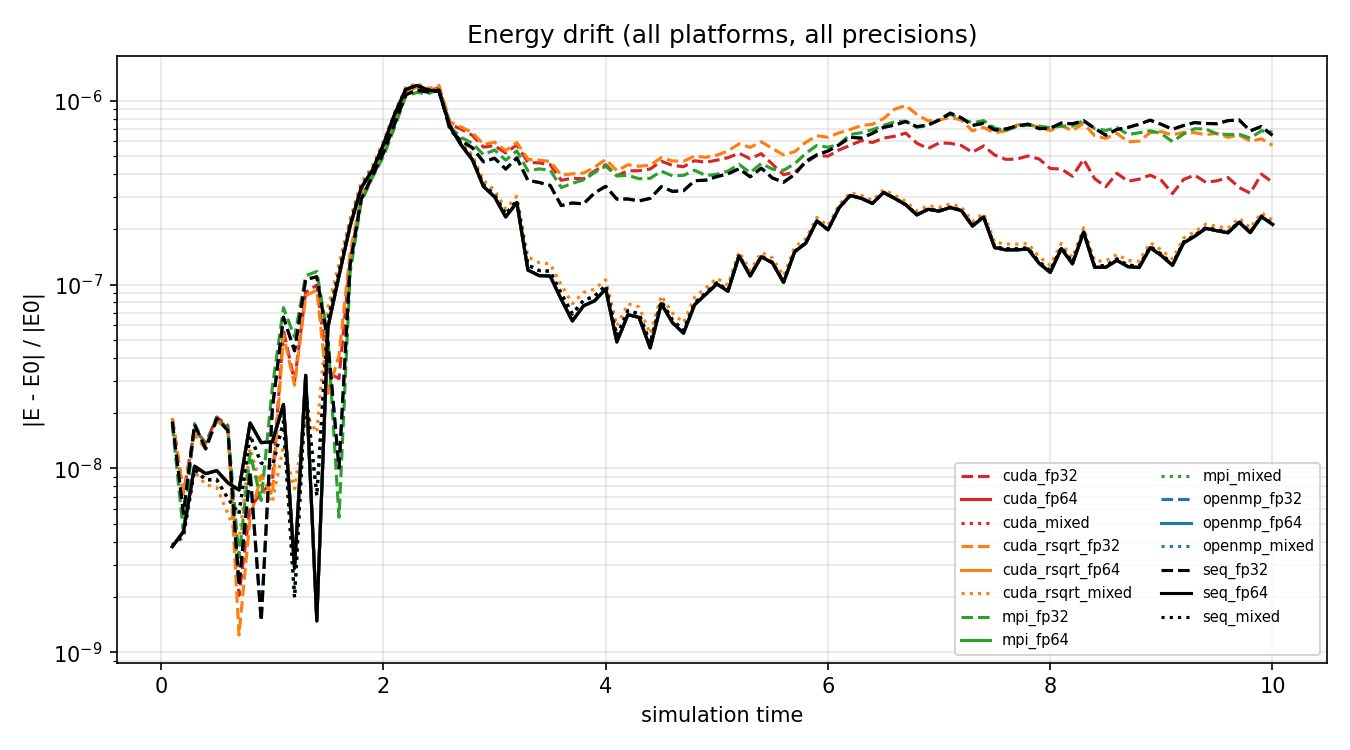

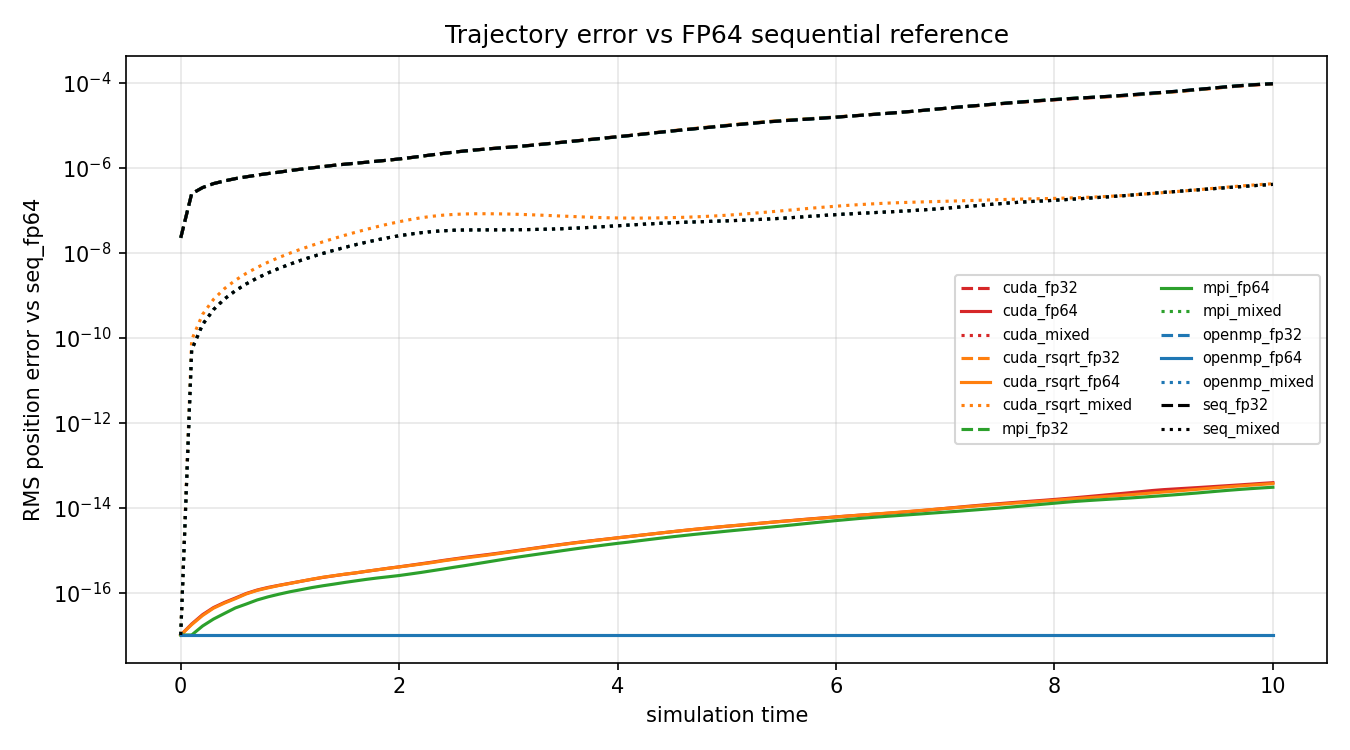

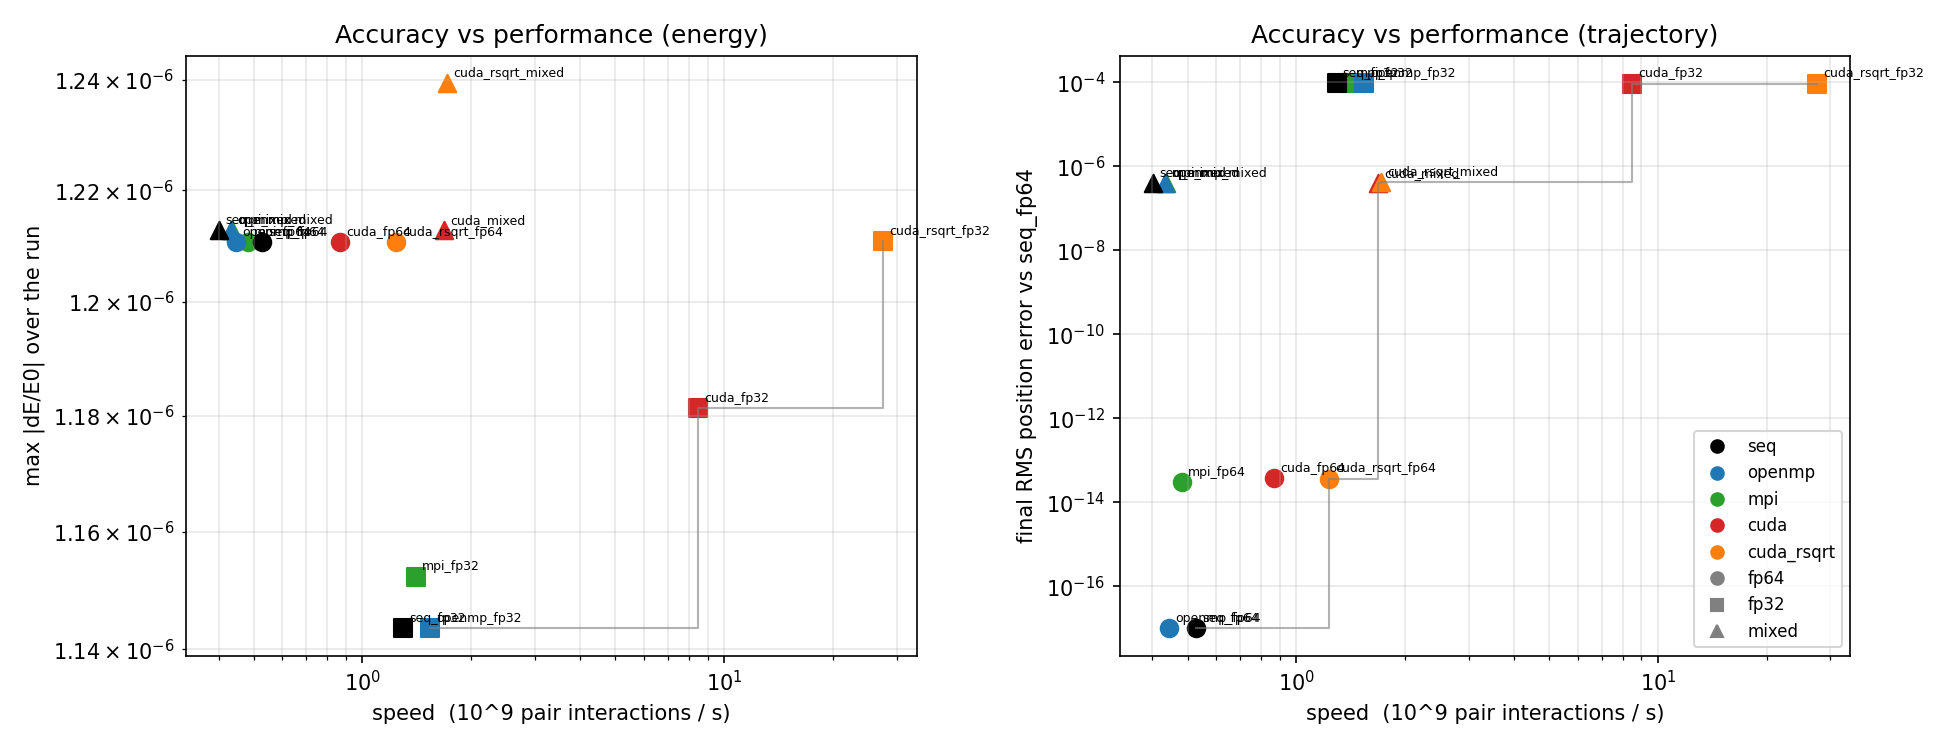

In [ ]:
from IPython.display import Image, display
for f in ['plot_energy_drift', 'plot_trajectory_error', 'plot_pareto']: display(Image(f'/content/nbody/acc/{f}.png'))

**How to read the results (for the discussion section)**
* *Energy drift* mostly measures the **integrator** (velocity-Verlet with dt = 1e-3 gives ≈ 1e-6 relative energy error) – so FP32 and mixed can look as good as FP64 on this metric. Lower the time step (edit `DT` in `nbody_common.hpp` and rebuild everything) if you want round-off to show up in the energy.
* *Trajectory error* is where precision shows: gravity is chaotic, so any perturbation (FP32 round-off, or even a different summation order) grows roughly exponentially with time. Expect FP64 platforms to agree to ~1e-13 or better for a long time, mixed ≈ 1e-8…1e-6, FP32 ≈ 1e-6 and growing – compare *statistics* (energy) as well as individual orbits.
* Speed: FP32 gives the biggest speedup on CPU (SIMD width ×2) and on consumer/T4 GPUs (FP64 is 1/32 rate); `mixed` keeps FP64 state but cheap FP32 pair math.

### Package everything for download

In [ ]:
import shutil
shutil.make_archive('/content/nbody_results', 'zip', '/content/nbody', 'results')
shutil.make_archive('/content/nbody_acc', 'zip', '/content/nbody', 'acc')
try:
    from google.colab import files
    files.download('/content/nbody_results.zip'); files.download('/content/nbody_acc.zip')
except Exception as e:
    print('zips are in /content:', e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>